# Machine Learning Cybersecurity Project

## Lab 2: Generative and Discriminative Classification

This notebook begins Lab 2 by constructing the required fixed evaluation protocol and completing Part 1: inspection of the numerical features. The work follows the Lab 1 rules: each task has a stated objective, preprocessing decisions use training data only, and every result is followed by a short interpretation.

## Task 1 - Reproducible notebook setup

**Objective.** Import only the packages needed for data handling, visualization, and stratified splitting. Declare the random seed and split proportions before examining any model results.

In [2]:
# Purpose: Declare the seed and 60/20/20 split proportions before model comparisons.
# Explain: A fixed seed makes allocation reproducible; it does not demonstrate robustness across datasets.

from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
TRAIN_FRACTION = 0.60
VALIDATION_FRACTION = 0.20
TEST_FRACTION = 0.20

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

setup = pd.Series({
    "random_seed": RANDOM_SEED,
    "training_fraction": TRAIN_FRACTION,
    "validation_fraction": VALIDATION_FRACTION,
    "test_fraction": TEST_FRACTION,
}, name="value")

display(setup.to_frame())

,value
random_seed,42.0
training_fraction,0.6
validation_fraction,0.2
test_fraction,0.2


### Interpretation

The seed and split proportions are fixed before data analysis. Reusing these values makes the partitions reproducible and ensures that every later classifier is compared on exactly the same rows.

## Task 2 - Load and concatenate the reduced CICIDS2017 files

**Objective.** Read every CSV in the extracted `MachineLearningCSV` directory, strip accidental whitespace from column names, and concatenate the files in a deterministic order. The source filename is retained for auditing only and will never be used as a predictor.

In [3]:
# Purpose: Load the reduced CSV files deterministically and attach audit provenance.
# Explain: Filenames and row numbers identify observations but are excluded from model predictors.

DATA_DIRECTORY = Path("MachineLearningCSV")

csv_files = sorted(
    DATA_DIRECTORY.rglob("*.csv"),
    key=lambda path: path.as_posix(),
)

if not csv_files:
    raise FileNotFoundError(
        "No CSV files were found. Extract MachineLearningCSV.zip into "
        "a MachineLearningCSV folder beside this notebook."
    )

frames = []
for csv_file in csv_files:
    frame = pd.read_csv(csv_file, encoding="cp1252", low_memory=False)
    frame.columns = frame.columns.str.strip()
    frame["source_file"] = csv_file.relative_to(DATA_DIRECTORY).as_posix()
    frame["source_row"] = np.arange(1, len(frame) + 1, dtype=np.int64)
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
del frames

load_summary = pd.Series({
    "source_files": len(csv_files),
    "rows_loaded": len(df),
    "columns_from_csv": len(df.columns) - 2,
}, name="value")

display(load_summary.to_frame())
display(df[["source_file", "source_row", "Label"]].head())

,value
source_files,8
rows_loaded,2830743
columns_from_csv,79


,source_file,source_row,Label
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,1,BENIGN
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2,BENIGN
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,3,BENIGN
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,4,BENIGN
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,5,BENIGN


### Interpretation

The output confirms how many reduced files and flow rows were loaded. Sorting the file paths makes ingestion reproducible. `source_file` and `source_row` preserve provenance for auditing, but they are metadata rather than behavioral predictors.

## Task 3 - Standardize labels and assign stable row identifiers

**Objective.** Remove surrounding whitespace, normalize the three documented Web Attack labels whose separator is corrupted in the reduced CSV, flag missing labels rather than silently discarding them, and create a stable identifier from the source filename and original row number.

In [4]:
# Purpose: Normalize documented label spelling issues and create stable source-based row IDs.
# Explain: Preserve the original category distinctions needed for multiclass stratification.

df["Label"] = df["Label"].astype("string").str.strip()

# The reduced Web Attack CSV contains a replacement character where the
# separator dash should appear. Normalize only the three documented labels.
web_attack_label_map = {
    "Web Attack ï¿½ Brute Force": "Web Attack - Brute Force",
    "Web Attack ï¿½ Sql Injection": "Web Attack - Sql Injection",
    "Web Attack ï¿½ XSS": "Web Attack - XSS",
    "Web Attack � Brute Force": "Web Attack - Brute Force",
    "Web Attack � Sql Injection": "Web Attack - Sql Injection",
    "Web Attack � XSS": "Web Attack - XSS",
}
labels_normalized = int(df["Label"].isin(web_attack_label_map).sum())
df["Label"] = df["Label"].replace(web_attack_label_map)

df["row_id"] = (
    df["source_file"].astype("string")
    + "::"
    + df["source_row"].astype("string")
)

label_audit = pd.Series({
    "rows": len(df),
    "unique_row_ids": df["row_id"].nunique(),
    "missing_labels": int(df["Label"].isna().sum()),
    "labels_normalized": labels_normalized,
    "distinct_labels": int(df["Label"].nunique(dropna=True)),
}, name="value")

assert df["row_id"].is_unique

display(label_audit.to_frame())
display(df["Label"].value_counts(dropna=False).rename("rows").to_frame())

,value
rows,2830743
unique_row_ids,2830743
missing_labels,0
labels_normalized,2180
distinct_labels,15


,rows
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


### Interpretation

Every physical CSV row now has a unique, traceable identifier. The audit reports how many corrupted Web Attack labels were normalized, while preserving their attack categories. The label table also exposes missing labels and class imbalance before any rows are removed. A missing label would require an explicit treatment because it cannot be used for supervised learning.

## Task 4 - Audit exact duplicate feature rows

**Objective.** Detect rows with identical predictor values before splitting. Repeated copies with the same label are removed deterministically by retaining their first source row. Identical feature vectors carrying different labels are retained and reported because the available predictors cannot distinguish their targets.

In [5]:
# Purpose: Remove extra copies of identical predictor-label pairs before splitting.
# Explain: Unlike Lab 1 complete records, this ignores provenance; retain conflicting-label evidence.

# Exclude the target and added identifiers from predictor comparisons.
# A unique row_id would otherwise make identical observations appear different.
audit_columns = {"Label", "source_file", "source_row", "row_id"}
predictor_columns = [column for column in df.columns if column not in audit_columns]

# keep=False marks EVERY member of a repeated-predictor group.
# This audit includes vectors repeated with either the same or different labels.
feature_duplicate_mask = df.duplicated(
    subset=predictor_columns,
    keep=False,
)

# Adding Label makes this a comparison of (predictors, label) pairs.
# keep="first" marks only extra copies, leaving one per pair.
# Opposite-label rows with the same predictors are not merged together.
same_label_repeated_mask = df.duplicated(
    subset=predictor_columns + ["Label"],
    keep="first",
)

# Hashing narrows the expensive exact conflict check to possible mixed-label groups.
duplicate_feature_rows = df.loc[
    feature_duplicate_mask,
    ["row_id", "Label"] + predictor_columns,
].copy()
duplicate_feature_rows["feature_hash"] = pd.util.hash_pandas_object(
    duplicate_feature_rows[predictor_columns],
    index=False,
).to_numpy()

hash_label_counts = duplicate_feature_rows.groupby(
    "feature_hash", sort=False
)["Label"].nunique(dropna=False)
mixed_label_hashes = hash_label_counts[hash_label_counts > 1].index

mixed_label_candidates = duplicate_feature_rows.loc[
    duplicate_feature_rows["feature_hash"].isin(mixed_label_hashes)
].copy()

if mixed_label_candidates.empty:
    conflict_examples = pd.DataFrame(
        columns=["conflict_group", "row_id", "Label"]
    )
    conflicting_feature_groups = 0
    conflicting_feature_rows = 0
else:
    # Exact grouping removes any possible hash-collision false positives.
    mixed_label_candidates["exact_group"] = mixed_label_candidates.groupby(
        predictor_columns,
        dropna=False,
        sort=False,
    ).ngroup()
    exact_label_counts = mixed_label_candidates.groupby(
        "exact_group", sort=False
    )["Label"].nunique(dropna=False)
    conflicting_group_ids = exact_label_counts[exact_label_counts > 1].index
    conflict_rows = mixed_label_candidates.loc[
        mixed_label_candidates["exact_group"].isin(conflicting_group_ids),
        ["exact_group", "row_id", "Label"],
    ].copy()
    conflict_rows["conflict_group"] = pd.factorize(
        conflict_rows["exact_group"], sort=False
    )[0] + 1
    conflict_examples = conflict_rows[
        ["conflict_group", "row_id", "Label"]
    ].head(20)
    conflicting_feature_groups = len(conflicting_group_ids)
    conflicting_feature_rows = len(conflict_rows)

# Keep one row per original predictor-label pair; retain opposite-label representatives.
model_df = df.loc[~same_label_repeated_mask].copy().reset_index(drop=True)

duplicate_audit = pd.Series({
    "rows_in_duplicate_feature_groups": int(feature_duplicate_mask.sum()),
    "same_label_repeated_copies_removed": int(same_label_repeated_mask.sum()),
    "conflicting_feature_groups_retained": int(conflicting_feature_groups),
    "rows_in_conflicting_feature_groups": int(conflicting_feature_rows),
    "rows_retained_for_modeling": len(model_df),
}, name="value")

display(duplicate_audit.to_frame())
print("First conflicting-label examples (if any):")
display(conflict_examples)

del (
    df,
    duplicate_feature_rows,
    mixed_label_candidates,
    feature_duplicate_mask,
    same_label_repeated_mask,
)

,value
rows_in_duplicate_feature_groups,404558
same_label_repeated_copies_removed,308381
conflicting_feature_groups_retained,698
rows_in_conflicting_feature_groups,7020
rows_retained_for_modeling,2522362


First conflicting-label examples (if any):


,conflict_group,row_id,Label
15047,1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::15048,BENIGN
15057,2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::15058,BENIGN
19291,3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::19292,DDoS
40814,4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::40815,BENIGN
43645,3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::43646,DDoS
82257,5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::82258,DDoS
89342,3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::89343,DDoS
158001,3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::158002,DDoS
160885,6,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::160886,DDoS
218242,7,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::218243,BENIGN


### Interpretation

The audit distinguishes redundant same-label copies from genuine label ambiguity. Redundant copies are removed so that repeated rows cannot receive extra weight or cross partition boundaries. Conflicting feature vectors remain visible because deleting one label would silently resolve an ambiguity without evidence.

## Task 5 - Create the fixed multiclass-stratified split

**Objective.** Allocate 60% of the retained rows to training, 20% to validation, and 20% to test. Stratification uses the original multiclass traffic label. The same partitions will be reused for every binary and multiclass experiment in Lab 2.

In [6]:
# Purpose: Split cleaned rows once using original multiclass labels for stratification.
# Explain: Preserve rare-category proportions as feasible and reuse memberships across representations.

if model_df["Label"].isna().any():
    raise ValueError(
        "Missing labels were found. Document their treatment before splitting."
    )

# Split positions so features, labels, and provenance can remain aligned.
all_positions = np.arange(len(model_df))
# Reserve 40% and retain 60% for training, using seed 42.
# Stratify on individual attack types, not only the broad ATTACK label.
train_positions, temporary_positions = train_test_split(
    all_positions,
    test_size=VALIDATION_FRACTION + TEST_FRACTION,
    random_state=RANDOM_SEED,
    stratify=model_df["Label"],
)
# The test fraction is 0.20 / (0.20 + 0.20) = 0.5 of the reserve.
# Use labels indexed by temporary_positions to stratify those same rows.
# Binary targets are derived later without changing these memberships.
validation_positions, test_positions = train_test_split(
    temporary_positions,
    test_size=TEST_FRACTION / (VALIDATION_FRACTION + TEST_FRACTION),
    random_state=RANDOM_SEED,
    stratify=model_df.iloc[temporary_positions]["Label"],
)

partition = np.full(len(model_df), "", dtype=object)
partition[train_positions] = "train"
partition[validation_positions] = "validation"
partition[test_positions] = "test"
model_df["partition"] = pd.Categorical(
    partition,
    categories=["train", "validation", "test"],
    ordered=True,
)

assert (partition != "").all()
assert (
    len(train_positions)
    + len(validation_positions)
    + len(test_positions)
    == len(model_df)
)

split_sizes = model_df["partition"].value_counts(sort=False).rename("rows")
split_sizes = split_sizes.to_frame()
split_sizes["percentage"] = 100 * split_sizes["rows"] / len(model_df)

display(split_sizes)

,rows,percentage
partition,,
train,1513417,59.999992
validation,504472,19.999984
test,504473,20.000024


### Interpretation

The output verifies the requested 60/20/20 allocation and confirms that the partitions do not overlap. Stratifying on the multiclass label preserves rare attack categories as closely as their available counts allow. This random-row protocol measures in-distribution performance, not transfer to later days or unseen attack scenarios.

## Task 6 - Derive the binary label after splitting

**Objective.** Convert every non-benign traffic category to `ATTACK` only after the fixed multiclass split has been created. This prevents the broader binary label from changing how individual attack categories are distributed across partitions.

In [7]:
# Purpose: Derive BENIGN/ATTACK targets after fixing multiclass-stratified memberships.
# Explain: Only the target meaning changes; no flow moves between partitions.

model_df["binary_label"] = np.where(
    model_df["Label"].eq("BENIGN"),
    "BENIGN",
    "ATTACK",
)

binary_class_counts = pd.crosstab(
    model_df["binary_label"],
    model_df["partition"],
    rownames=["binary_label"],
    colnames=["partition"],
).reindex(
    index=["BENIGN", "ATTACK"],
    columns=["train", "validation", "test"],
    fill_value=0,
)

display(binary_class_counts)

partition,train,validation,test
binary_label,,,
BENIGN,1257890,419297,419297
ATTACK,255527,85175,85176


### Interpretation

The table shows the benign and attack counts inherited from the multiclass-stratified split. The expected imbalance is retained rather than hidden or artificially balanced. Later metrics must therefore include balanced accuracy and attack-specific precision, recall, and F1.

## Task 7 - Report and save the evaluation protocol

**Objective.** Report every multiclass count, including zeros, and save the stable row identifiers, partitions, seed, and split proportions. These saved assignments will be reused unchanged throughout Labs 2 and 3.

In [8]:
# Purpose: Save row memberships, labels, counts, and seed as the reusable evaluation protocol.
# Explain: Lab 3 restores these exact rows; models should not create fresh favorable splits.

label_order = sorted(model_df["Label"].unique())
multiclass_counts = pd.crosstab(
    model_df["Label"],
    model_df["partition"],
    rownames=["Label"],
    colnames=["partition"],
).reindex(
    index=label_order,
    columns=["train", "validation", "test"],
    fill_value=0,
)

ARTIFACT_DIRECTORY = Path("artifacts")
ARTIFACT_DIRECTORY.mkdir(exist_ok=True)

model_df[["row_id", "Label", "binary_label", "partition"]].to_csv(
    ARTIFACT_DIRECTORY / "fixed_split_assignments.csv.gz",
    index=False,
    compression="gzip",
)

split_configuration = {
    "random_seed": RANDOM_SEED,
    "training_fraction": TRAIN_FRACTION,
    "validation_fraction": VALIDATION_FRACTION,
    "test_fraction": TEST_FRACTION,
    "stratification_label": "original multiclass Label",
    "rows": int(len(model_df)),
}
with open(
    ARTIFACT_DIRECTORY / "fixed_split_config.json",
    "w",
    encoding="utf-8",
) as configuration_file:
    json.dump(split_configuration, configuration_file, indent=2)

print("MULTICLASS COUNTS")
display(multiclass_counts)
print("BINARY COUNTS")
display(binary_class_counts)
print("SAVED CONFIGURATION")
display(pd.Series(split_configuration, name="value").to_frame())

MULTICLASS COUNTS


partition,train,validation,test
Label,,,
BENIGN,1257890,419297,419297
Bot,1172,391,390
DDoS,76809,25603,25604
DoS GoldenEye,6172,2057,2057
DoS Hulk,103709,34570,34570
DoS Slowhttptest,3137,1045,1046
DoS slowloris,3231,1077,1077
FTP-Patator,3560,1186,1187
Heartbleed,7,2,2


BINARY COUNTS


partition,train,validation,test
binary_label,,,
BENIGN,1257890,419297,419297
ATTACK,255527,85175,85176


SAVED CONFIGURATION


,value
random_seed,42
training_fraction,0.6
validation_fraction,0.2
test_fraction,0.2
stratification_label,original multiclass Label
rows,2522362


### Interpretation

The tables document the exact populations available to every later experiment. The compressed assignment file preserves row membership, while the JSON file records the seed and split policy. These files prevent accidental repartitioning when binary, multiclass, and Lab 3 models are compared.

# Part 1 - Inspect the numerical features

## Task 8.1 - Training-only numerical diagnostics

**Objective.** Using training rows only, identify missing and infinite values, constants, and zero or very small within-class variances separately for benign and attack traffic. Destination Port is excluded because it is a categorical service identifier.

A within-class variance is flagged as **very small** when it is positive but no more than $10^{-8}$ of that feature's overall training variance. This scale-relative rule is suitable for features measured in different units.

In [9]:
# Purpose: Screen numerical features on training, separately within BENIGN and ATTACK.
# Explain: Within-class zero variance can destabilize Gaussian likelihoods even if a feature varies globally.

SMALL_VARIANCE_RATIO = 1e-8

non_predictor_columns = {
    "Label",
    "binary_label",
    "partition",
    "source_file",
    "source_row",
    "row_id",
}

candidate_numerical_features = [
    column
    for column in model_df.columns
    if column not in non_predictor_columns
    and column != "Destination Port"
]

training_mask = model_df["partition"].eq("train")
training_binary_label = model_df.loc[training_mask, "binary_label"]
benign_mask = training_binary_label.eq("BENIGN")
attack_mask = training_binary_label.eq("ATTACK")

diagnostic_rows = []
for feature in candidate_numerical_features:
    values = pd.to_numeric(
        model_df.loc[training_mask, feature],
        errors="coerce",
    )
    positive_infinity = int(np.isposinf(values.to_numpy()).sum())
    negative_infinity = int(np.isneginf(values.to_numpy()).sum())
    missing = int(values.isna().sum())
    finite_values = values[np.isfinite(values)]
    finite_unique = int(finite_values.nunique())
    overall_variance = finite_values.var(ddof=0)

    benign_values = values.loc[benign_mask]
    benign_values = benign_values[np.isfinite(benign_values)]
    attack_values = values.loc[attack_mask]
    attack_values = attack_values[np.isfinite(attack_values)]

    benign_variance = benign_values.var(ddof=0)
    attack_variance = attack_values.var(ddof=0)

    if pd.notna(overall_variance) and overall_variance > 0:
        benign_variance_ratio = benign_variance / overall_variance
        attack_variance_ratio = attack_variance / overall_variance
    else:
        benign_variance_ratio = np.nan
        attack_variance_ratio = np.nan

    diagnostic_rows.append({
        "feature": feature,
        "missing": missing,
        "positive_infinity": positive_infinity,
        "negative_infinity": negative_infinity,
        "finite_unique_values": finite_unique,
        "is_constant": finite_unique <= 1,
        "benign_variance": benign_variance,
        "attack_variance": attack_variance,
        "benign_variance_ratio": benign_variance_ratio,
        "attack_variance_ratio": attack_variance_ratio,
        "benign_zero_variance": pd.notna(benign_variance) and benign_variance == 0,
        "attack_zero_variance": pd.notna(attack_variance) and attack_variance == 0,
        "benign_small_variance": (
            pd.notna(benign_variance_ratio)
            and 0 < benign_variance_ratio <= SMALL_VARIANCE_RATIO
        ),
        "attack_small_variance": (
            pd.notna(attack_variance_ratio)
            and 0 < attack_variance_ratio <= SMALL_VARIANCE_RATIO
        ),
        "finite_minimum": finite_values.min() if len(finite_values) else np.nan,
        "skewness": finite_values.skew() if len(finite_values) >= 3 else np.nan,
    })

feature_diagnostics = pd.DataFrame(diagnostic_rows).set_index("feature")
feature_diagnostics["nonfinite_total"] = (
    feature_diagnostics["missing"]
    + feature_diagnostics["positive_infinity"]
    + feature_diagnostics["negative_infinity"]
)

attention_mask = (
    feature_diagnostics["nonfinite_total"].gt(0)
    | feature_diagnostics["is_constant"]
    | feature_diagnostics["benign_zero_variance"]
    | feature_diagnostics["attack_zero_variance"]
    | feature_diagnostics["benign_small_variance"]
    | feature_diagnostics["attack_small_variance"]
)

attention_diagnostics = feature_diagnostics.loc[attention_mask, [
    "nonfinite_total",
    "is_constant",
    "benign_variance_ratio",
    "attack_variance_ratio",
    "benign_zero_variance",
    "attack_zero_variance",
    "benign_small_variance",
    "attack_small_variance",
]]

print(f"Candidate numerical features: {len(candidate_numerical_features)}")
print(f"Very-small variance ratio threshold: {SMALL_VARIANCE_RATIO:g}")
display(attention_diagnostics)

Candidate numerical features: 77
Very-small variance ratio threshold: 1e-08


,nonfinite_total,is_constant,benign_variance_ratio,attack_variance_ratio,benign_zero_variance,attack_zero_variance,benign_small_variance,attack_small_variance
feature,,,,,,,,
Flow Bytes/s,919,False,1.196535,2.989877e-02,False,False,False,False
Flow Packets/s,919,False,1.162693,1.718959e-01,False,False,False,False
Bwd PSH Flags,0,True,NaN,NaN,True,True,False,False
Fwd URG Flags,0,False,1.203132,0.000000e+00,False,True,False,False
Bwd URG Flags,0,True,NaN,NaN,True,True,False,False
Fwd Header Length,0,False,1.203139,3.941154e-10,False,False,False,True
RST Flag Count,0,False,1.203073,0.000000e+00,False,True,False,False
CWE Flag Count,0,False,1.203132,0.000000e+00,False,True,False,False
ECE Flag Count,0,False,1.203073,0.000000e+00,False,True,False,False


### Interpretation

The table contains only features requiring attention. Constants provide no discrimination and will be removed. Non-finite values will be replaced later using medians learned from training only. A feature with zero or very small variance in either class is retained initially but flagged because Gaussian Naive Bayes may require stronger variance smoothing for a stable likelihood estimate.

## Task 8.2 - Representative class-conditional histograms

**Objective.** Compare benign and attack distributions for several behavior-oriented measurements. A fixed training-only sample is used only to keep plotting practical. The displayed range ends at the training sample's 99.5th percentile so extreme tails do not hide the main distribution; this visual clipping does not remove or modify modeling rows.

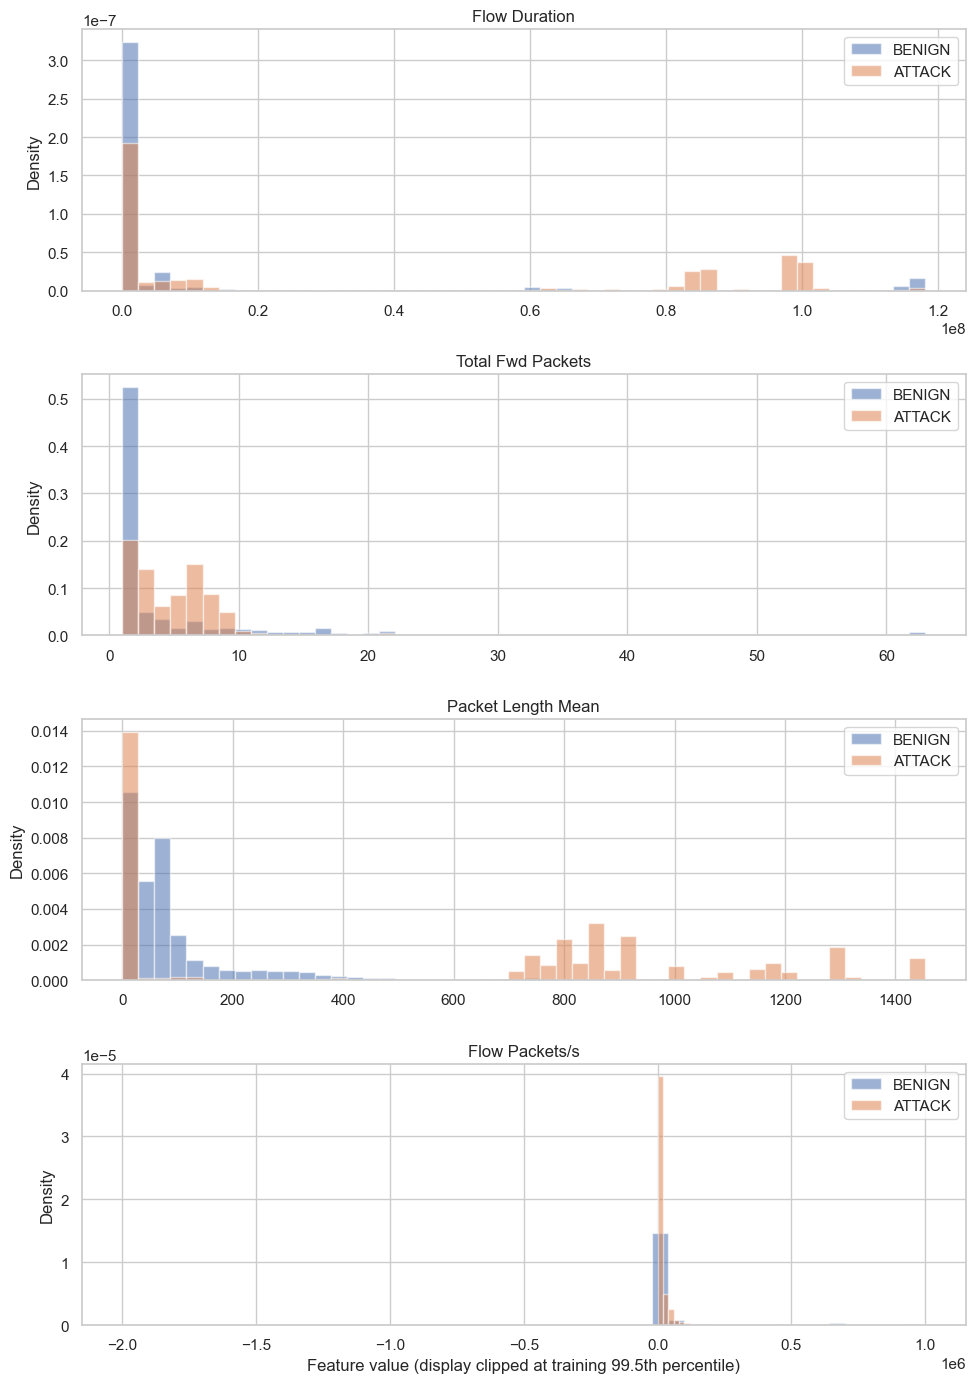

In [10]:
# Purpose: Inspect representative class-conditional numerical distributions on training.
# Explain: Skew, multiple peaks, and overlap help assess Gaussian modeling assumptions.

requested_representative_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Packet Length Mean",
    "Flow Packets/s",
]
representative_features = [
    feature
    for feature in requested_representative_features
    if feature in candidate_numerical_features
    and not feature_diagnostics.loc[feature, "is_constant"]
]

training_indices = model_df.index[training_mask]
benign_training_indices = training_indices[training_binary_label.eq("BENIGN").to_numpy()]
attack_training_indices = training_indices[training_binary_label.eq("ATTACK").to_numpy()]

benign_plot_indices = pd.Series(benign_training_indices).sample(
    n=min(100_000, len(benign_training_indices)),
    random_state=RANDOM_SEED,
).to_numpy()
attack_plot_indices = pd.Series(attack_training_indices).sample(
    n=min(100_000, len(attack_training_indices)),
    random_state=RANDOM_SEED,
).to_numpy()

figure, axes = plt.subplots(
    len(representative_features),
    1,
    figsize=(10, 3.5 * len(representative_features)),
)
axes = np.atleast_1d(axes)

for axis, feature in zip(axes, representative_features):
    benign_values = pd.to_numeric(
        model_df.loc[benign_plot_indices, feature], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()
    attack_values = pd.to_numeric(
        model_df.loc[attack_plot_indices, feature], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()
    combined_values = pd.concat([benign_values, attack_values])
    upper_limit = combined_values.quantile(0.995)
    lower_limit = combined_values.min()

    axis.hist(
        benign_values.clip(lower=lower_limit, upper=upper_limit),
        bins=50,
        density=True,
        alpha=0.55,
        label="BENIGN",
    )
    axis.hist(
        attack_values.clip(lower=lower_limit, upper=upper_limit),
        bins=50,
        density=True,
        alpha=0.55,
        label="ATTACK",
    )
    axis.set_title(feature)
    axis.set_ylabel("Density")
    axis.legend()

axes[-1].set_xlabel("Feature value (display clipped at training 99.5th percentile)")
plt.tight_layout()
plt.show()

### Interpretation

The histograms show whether each feature has different class-conditional shapes or substantial overlap. 
they show how each feature is distributed separately for benign and attack traffic.

From the plots:

- Flow Duration has considerable overlap, although attacks contain several high-duration concentrations.
- Total Fwd Packets also overlaps, but attacks are more concentrated around several packet counts.
- Packet Length Mean shows the clearest class difference: many attacks occupy larger packet-size ranges.
- Flow Packets/s is extremely concentrated and contains non-finite values, making it harder to model directly.

## Task 8.3 - Test a log transformation

**Objective.** Among nonconstant, nonnegative numerical features with at least 20 observed values, select the feature with the strongest positive training skewness. Requiring several observed values avoids treating a rare binary indicator as a continuous skewed measurement. Compare its class-conditional distribution and skewness before and after `log(1+x)`. Keep the transformation only when it reduces absolute skewness.

,value
selected_feature,Total Length of Fwd Packets
raw_skewness,765.395242
log1p_skewness,-0.160581
absolute_skewness_reduced,True
decision,apply log1p


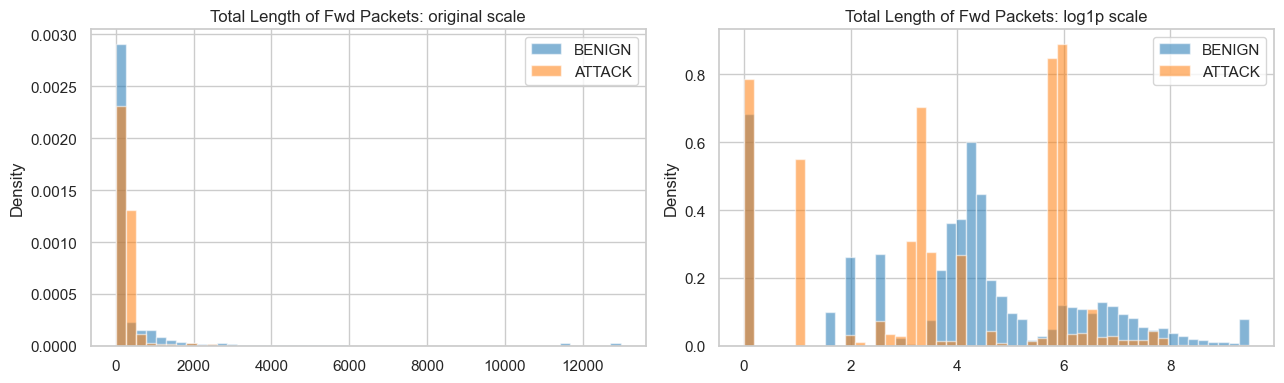

In [11]:
# Purpose: Compare a nonnegative skewed feature before and after log1p on training.
# Explain: Keep the transformation when absolute skewness decreases; this does not ensure Gaussianity.

nonnegative_skew_candidates = feature_diagnostics.loc[
    feature_diagnostics["finite_minimum"].ge(0)
    & ~feature_diagnostics["is_constant"]
    & feature_diagnostics["finite_unique_values"].ge(20)
    & feature_diagnostics["skewness"].notna()
    & feature_diagnostics["skewness"].gt(1)
].copy()

log_feature = nonnegative_skew_candidates["skewness"].idxmax()
log_training_values = pd.to_numeric(
    model_df.loc[training_mask, log_feature],
    errors="coerce",
).replace([np.inf, -np.inf], np.nan)
finite_log_training_values = log_training_values.dropna()
transformed_training_values = np.log1p(finite_log_training_values)

raw_skewness = finite_log_training_values.skew()
log1p_skewness = transformed_training_values.skew()
keep_log1p = abs(log1p_skewness) < abs(raw_skewness)

log_decision = pd.Series({
    "selected_feature": log_feature,
    "raw_skewness": raw_skewness,
    "log1p_skewness": log1p_skewness,
    "absolute_skewness_reduced": keep_log1p,
    "decision": "apply log1p" if keep_log1p else "retain original scale",
}, name="value")
display(log_decision.to_frame())

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for class_label, color in [("BENIGN", "tab:blue"), ("ATTACK", "tab:orange")]:
    class_indices = (
        benign_plot_indices if class_label == "BENIGN" else attack_plot_indices
    )
    class_values = pd.to_numeric(
        model_df.loc[class_indices, log_feature], errors="coerce"
    ).replace([np.inf, -np.inf], np.nan).dropna()
    raw_upper_limit = finite_log_training_values.quantile(0.995)
    axes[0].hist(
        class_values.clip(upper=raw_upper_limit),
        bins=50,
        density=True,
        alpha=0.55,
        color=color,
        label=class_label,
    )
    axes[1].hist(
        np.log1p(class_values).clip(upper=np.log1p(raw_upper_limit)),
        bins=50,
        density=True,
        alpha=0.55,
        color=color,
        label=class_label,
    )

axes[0].set_title(f"{log_feature}: original scale")
axes[1].set_title(f"{log_feature}: log1p scale")
for axis in axes:
    axis.set_ylabel("Density")
    axis.legend()
plt.tight_layout()
plt.show()

### Interpretation

The skewness table provides an explicit transformation decision rather than assuming that logarithms always help. If absolute skewness decreases, `log1p` will be fitted as part of the later training pipeline; it is valid for zero values and compresses the long right tail. The transformation does not make Gaussianity mandatory, but it can make Gaussian class-conditional estimates less distorted.

## Task 8.4 - Produce the required feature-action table

**Objective.** Summarize only features that require treatment. Constant and explicitly repeated features are removed. Non-finite values receive training-median replacement. Small within-class variances are retained with a warning for possible Gaussian variance smoothing. The selected skewed feature is transformed only if the preceding comparison supports it.

In [12]:
# Purpose: Record which numerical features need removal, transformation, or variance monitoring.
# Explain: A verified repeated column and training constants add no new discrimination.

repeated_header_feature = "Fwd Header Length.1"
repeated_header_confirmed = (
    repeated_header_feature in model_df.columns
    and "Fwd Header Length" in model_df.columns
    and model_df.loc[training_mask, repeated_header_feature].equals(
        model_df.loc[training_mask, "Fwd Header Length"]
    )
)

action_rows = []
for feature, row in feature_diagnostics.iterrows():
    issues = []
    treatments = []

    if feature == repeated_header_feature and repeated_header_confirmed:
        issues.append("duplicates Fwd Header Length")
        treatments.append("remove repeated feature")
    elif row["is_constant"]:
        issues.append("constant in training")
        treatments.append("remove")
    else:
        if row["nonfinite_total"] > 0:
            issues.append(f"{int(row['nonfinite_total'])} non-finite training values")
            treatments.append("replace using training median")
        if row["benign_zero_variance"]:
            issues.append("zero variance within BENIGN")
        elif row["benign_small_variance"]:
            issues.append("very small variance within BENIGN")
        if row["attack_zero_variance"]:
            issues.append("zero variance within ATTACK")
        elif row["attack_small_variance"]:
            issues.append("very small variance within ATTACK")
        if (
            row["benign_zero_variance"]
            or row["benign_small_variance"]
            or row["attack_zero_variance"]
            or row["attack_small_variance"]
        ):
            treatments.append("retain; monitor Gaussian variance smoothing")
        if feature == log_feature and keep_log1p:
            issues.append("strong nonnegative right skew")
            treatments.append("apply log1p after non-finite replacement")

    if issues:
        action_rows.append({
            "feature": feature,
            "observed_issue": "; ".join(issues),
            "action": "; ".join(dict.fromkeys(treatments)),
        })

feature_action_table = (
    pd.DataFrame(action_rows)
    .sort_values("feature")
    .reset_index(drop=True)
)

display(feature_action_table)

,feature,observed_issue,action
0,Bwd Avg Bulk Rate,constant in training,remove
1,Bwd Avg Bytes/Bulk,constant in training,remove
2,Bwd Avg Packets/Bulk,constant in training,remove
3,Bwd PSH Flags,constant in training,remove
4,Bwd URG Flags,constant in training,remove
5,CWE Flag Count,zero variance within ATTACK,retain; monitor Gaussian variance smoothing
6,ECE Flag Count,zero variance within ATTACK,retain; monitor Gaussian variance smoothing
7,Flow Bytes/s,919 non-finite training values,replace using training median
8,Flow Packets/s,919 non-finite training values,replace using training median
9,Fwd Avg Bulk Rate,constant in training,remove


### Part 1 interpretation

The final table records every treatment without silently changing the data. Constants and the verified repeated header-length column are removed because they add no new information. Non-finite values will be replaced using training medians inside later preprocessing pipelines. Features with small within-class variance remain available, but their behavior will guide validation-based Gaussian variance smoothing. The accepted `log1p` decision will be applied consistently to training, validation, and test rows using the transformation selected from training data only.

The next lab stage is Part 2: constructing the numerical subset, destination-port-only representation, and complete eligible hybrid representation.

# Part 2 - Three feature representations

## Representation A - Numerical subset

**Objective.** Select 10 behavior-oriented numerical features covering duration, packet counts, transferred bytes, packet sizes, timing, rate, TCP state, and activity. Replace non-finite values with medians learned from training only, apply the Part 1 `log1p` decision to `Total Length of Fwd Packets`, and standardize using training means and standard deviations. Apply the fitted preprocessing unchanged to validation and test data.

In [13]:
# Purpose: Construct representation A: ten numerical behavioral features with fitted preprocessing.
# Explain: Learn medians/scales from training; transform all partitions using the same parameters.

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_subset_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Flow Packets/s",
    "Flow IAT Mean",
    "SYN Flag Count",
    "Active Mean",
]

feature_roles = {
    "Flow Duration": "connection duration",
    "Total Fwd Packets": "forward packet count",
    "Total Backward Packets": "backward packet count",
    "Total Length of Fwd Packets": "forward byte volume",
    "Fwd Packet Length Mean": "forward packet size",
    "Bwd Packet Length Mean": "backward packet size",
    "Flow Packets/s": "packet transmission rate",
    "Flow IAT Mean": "inter-arrival timing",
    "SYN Flag Count": "TCP connection state",
    "Active Mean": "active-period behavior",
}

missing_selected_features = sorted(
    set(numerical_subset_features) - set(model_df.columns)
)
if missing_selected_features:
    raise KeyError(f"Selected features not found: {missing_selected_features}")

selected_constant_features = [
    feature
    for feature in numerical_subset_features
    if feature_diagnostics.loc[feature, "is_constant"]
]
if selected_constant_features:
    raise ValueError(
        f"Constant features cannot enter the subset: {selected_constant_features}"
    )

train_mask = model_df["partition"].eq("train")
validation_mask = model_df["partition"].eq("validation")
test_mask = model_df["partition"].eq("test")

X_train_numerical_raw = model_df.loc[
    train_mask, numerical_subset_features
].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X_validation_numerical_raw = model_df.loc[
    validation_mask, numerical_subset_features
].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X_test_numerical_raw = model_df.loc[
    test_mask, numerical_subset_features
].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

nonfinite_counts = pd.DataFrame({
    "train": X_train_numerical_raw.isna().sum(),
    "validation": X_validation_numerical_raw.isna().sum(),
    "test": X_test_numerical_raw.isna().sum(),
})

# Median imputation is less sensitive to extreme values than mean imputation.
numerical_imputer = SimpleImputer(strategy="median")
# Store training medians in numerical_imputer.statistics_.
numerical_imputer.fit(X_train_numerical_raw)

X_train_numerical_ready = pd.DataFrame(
    numerical_imputer.transform(X_train_numerical_raw),
    columns=numerical_subset_features,
    index=X_train_numerical_raw.index,
)
X_validation_numerical_ready = pd.DataFrame(
    numerical_imputer.transform(X_validation_numerical_raw),
    columns=numerical_subset_features,
    index=X_validation_numerical_raw.index,
)
X_test_numerical_ready = pd.DataFrame(
    numerical_imputer.transform(X_test_numerical_raw),
    columns=numerical_subset_features,
    index=X_test_numerical_raw.index,
)

log1p_feature = "Total Length of Fwd Packets"
for prepared_data in [
    X_train_numerical_ready,
    X_validation_numerical_ready,
    X_test_numerical_ready,
]:
    if prepared_data[log1p_feature].lt(0).any():
        raise ValueError(f"Negative values found in {log1p_feature}")
    prepared_data[log1p_feature] = np.log1p(
        prepared_data[log1p_feature]
    )

# StandardScaler uses z = (x - training_mean) / training_scale.
numerical_scaler = StandardScaler()
# Only training values determine the centering and scale parameters.
numerical_scaler.fit(X_train_numerical_ready)

# Transform training values and restore their feature names and row index.
X_train_numerical = pd.DataFrame(
    numerical_scaler.transform(X_train_numerical_ready),
    columns=numerical_subset_features,
    index=X_train_numerical_ready.index,
)
# Apply the fixed training rule to validation, without learning from it.
X_validation_numerical = pd.DataFrame(
    numerical_scaler.transform(X_validation_numerical_ready),
    columns=numerical_subset_features,
    index=X_validation_numerical_ready.index,
)
# Apply exactly that same fixed rule to test.
X_test_numerical = pd.DataFrame(
    numerical_scaler.transform(X_test_numerical_ready),
    columns=numerical_subset_features,
    index=X_test_numerical_ready.index,
)

assert np.isfinite(X_train_numerical.to_numpy()).all()
assert np.isfinite(X_validation_numerical.to_numpy()).all()
assert np.isfinite(X_test_numerical.to_numpy()).all()

numerical_preprocessing_parameters = pd.DataFrame({
    "training_median": numerical_imputer.statistics_,
    "training_mean_after_transform": numerical_scaler.mean_,
    "training_scale": numerical_scaler.scale_,
}, index=numerical_subset_features)

numerical_subset_table = pd.DataFrame({
    "feature": numerical_subset_features,
    "behavior represented": [
        feature_roles[feature] for feature in numerical_subset_features
    ],
    "transformation": [
        "training median, log1p, standardize"
        if feature == log1p_feature
        else "training median, standardize"
        for feature in numerical_subset_features
    ],
})

numerical_subset_dimensions = pd.DataFrame({
    "rows": [
        len(X_train_numerical),
        len(X_validation_numerical),
        len(X_test_numerical),
    ],
    "features": [
        X_train_numerical.shape[1],
        X_validation_numerical.shape[1],
        X_test_numerical.shape[1],
    ],
}, index=["train", "validation", "test"])

representation_a_summary = pd.DataFrame([{
    "representation": "Numerical subset",
    "source_features": len(numerical_subset_features),
    "transformations": "training-median imputation; selected log1p; standardization",
    "final_dimension": X_train_numerical.shape[1],
}])

print("SELECTED FEATURES")
display(numerical_subset_table)
print("NON-FINITE VALUES BEFORE TRAINING-MEDIAN IMPUTATION")
display(nonfinite_counts.loc[nonfinite_counts.sum(axis=1).gt(0)])
print("FINAL DIMENSIONS")
display(numerical_subset_dimensions)
display(representation_a_summary)

del (
    X_train_numerical_raw,
    X_validation_numerical_raw,
    X_test_numerical_raw,
    X_train_numerical_ready,
    X_validation_numerical_ready,
    X_test_numerical_ready,
)

SELECTED FEATURES


,feature,behavior represented,transformation
0,Flow Duration,connection duration,"training median, standardize"
1,Total Fwd Packets,forward packet count,"training median, standardize"
2,Total Backward Packets,backward packet count,"training median, standardize"
3,Total Length of Fwd Packets,forward byte volume,"training median, log1p, standardize"
4,Fwd Packet Length Mean,forward packet size,"training median, standardize"
5,Bwd Packet Length Mean,backward packet size,"training median, standardize"
6,Flow Packets/s,packet transmission rate,"training median, standardize"
7,Flow IAT Mean,inter-arrival timing,"training median, standardize"
8,SYN Flag Count,TCP connection state,"training median, standardize"
9,Active Mean,active-period behavior,"training median, standardize"


NON-FINITE VALUES BEFORE TRAINING-MEDIAN IMPUTATION


,train,validation,test
Flow Packets/s,919,322,323


FINAL DIMENSIONS


,rows,features
train,1513417,10
validation,504472,10
test,504473,10


,representation,source_features,transformations,final_dimension
0,Numerical subset,10,training-median imputation; selected log1p; standardization,10


### Interpretation

The numerical representation contains 10 behavioral features and preserves the fixed train, validation, and test rows. The non-finite table documents every value replaced; medians are learned only from training. `Total Length of Fwd Packets` receives the `log1p` transformation justified in Part 1, and all final columns are standardized using training statistics. The fitted imputer and scaler are retained so exactly the same preprocessing can be used later with Gaussian Naive Bayes, logistic regression, and the decision tree.

## Representation B - Destination port

**Objective.** Treat `Destination Port` as a categorical service identifier rather than a continuous number. Learn the observed port levels from training only, reserve an explicit `other` level, map missing, invalid, or previously unseen validation/test ports to `other`, and produce sparse one-hot matrices for Multinomial Naive Bayes, logistic regression, and the decision tree.

In [14]:
# Purpose: Construct representation B: sparse one-hot Destination Port with a training vocabulary.
# Explain: Reserve other for invalid or unseen ports; numerical distance between port IDs is meaningless.

from sklearn.preprocessing import OneHotEncoder

OTHER_PORT = -1

def normalize_destination_port(port_series):
    # Convert unparseable values to NaN rather than inventing valid ports.
    numeric_ports = pd.to_numeric(port_series, errors="coerce").to_numpy(
        dtype=float,
        na_value=np.nan,
    )
    # A valid port must be finite, between 0 and 65535, and integer-valued.
    valid_ports = (
        np.isfinite(numeric_ports)
        & (numeric_ports >= 0)
        & (numeric_ports <= 65535)
        & (numeric_ports == np.floor(numeric_ports))
    )
    # Initialize every row as other; overwrite only the verified valid entries.
    normalized_ports = np.full(
        len(numeric_ports),
        OTHER_PORT,
        dtype=np.int32,
    )
    normalized_ports[valid_ports] = numeric_ports[valid_ports].astype(np.int32)
    return normalized_ports

train_port_raw = normalize_destination_port(
    model_df.loc[train_mask, "Destination Port"]
)
validation_port_raw = normalize_destination_port(
    model_df.loc[validation_mask, "Destination Port"]
)
test_port_raw = normalize_destination_port(
    model_df.loc[test_mask, "Destination Port"]
)

# Only training ports define the vocabulary; valid unseen held-out ports map to other.
training_observed_ports = np.unique(
    train_port_raw[train_port_raw != OTHER_PORT]
)
port_levels = np.sort(
    np.append(training_observed_ports, OTHER_PORT).astype(np.int32)
)

validation_known_mask = np.isin(
    validation_port_raw, training_observed_ports
)
test_known_mask = np.isin(
    test_port_raw, training_observed_ports
)

train_port_mapped = train_port_raw.copy()
validation_port_mapped = np.where(
    validation_known_mask, validation_port_raw, OTHER_PORT
).astype(np.int32)
test_port_mapped = np.where(
    test_known_mask, test_port_raw, OTHER_PORT
).astype(np.int32)

# Create sparse indicators: many columns encode ONE categorical source feature.
port_encoder = OneHotEncoder(
    categories=[port_levels],
    handle_unknown="error",
    sparse_output=True,
    dtype=np.float32,
)
X_train_port = port_encoder.fit_transform(
    train_port_mapped.reshape(-1, 1)
)
X_validation_port = port_encoder.transform(
    validation_port_mapped.reshape(-1, 1)
)
X_test_port = port_encoder.transform(
    test_port_mapped.reshape(-1, 1)
)

port_feature_names = np.array([
    "Destination Port=other"
    if port == OTHER_PORT
    else f"Destination Port={port}"
    for port in port_levels
])

validation_unseen_mask = (
    (validation_port_raw != OTHER_PORT)
    & ~validation_known_mask
)
test_unseen_mask = (
    (test_port_raw != OTHER_PORT)
    & ~test_known_mask
)

port_mapping_audit = pd.DataFrame({
    "rows": [
        len(train_port_mapped),
        len(validation_port_mapped),
        len(test_port_mapped),
    ],
    "missing_or_invalid_rows": [
        int((train_port_raw == OTHER_PORT).sum()),
        int((validation_port_raw == OTHER_PORT).sum()),
        int((test_port_raw == OTHER_PORT).sum()),
    ],
    "unseen_port_rows": [
        0,
        int(validation_unseen_mask.sum()),
        int(test_unseen_mask.sum()),
    ],
    "unique_unseen_ports": [
        0,
        int(np.unique(validation_port_raw[validation_unseen_mask]).size),
        int(np.unique(test_port_raw[test_unseen_mask]).size),
    ],
    "mapped_to_other_rows": [
        int((train_port_mapped == OTHER_PORT).sum()),
        int((validation_port_mapped == OTHER_PORT).sum()),
        int((test_port_mapped == OTHER_PORT).sum()),
    ],
}, index=["train", "validation", "test"])

port_dimensions = pd.DataFrame({
    "rows": [
        X_train_port.shape[0],
        X_validation_port.shape[0],
        X_test_port.shape[0],
    ],
    "one_hot_features": [
        X_train_port.shape[1],
        X_validation_port.shape[1],
        X_test_port.shape[1],
    ],
}, index=["train", "validation", "test"])

assert X_train_port.shape[1] == len(training_observed_ports) + 1
assert X_validation_port.shape[1] == X_train_port.shape[1]
assert X_test_port.shape[1] == X_train_port.shape[1]
assert np.all(X_train_port.getnnz(axis=1) == 1)
assert np.all(X_validation_port.getnnz(axis=1) == 1)
assert np.all(X_test_port.getnnz(axis=1) == 1)

representation_b_summary = pd.DataFrame([{
    "representation": "Destination port",
    "source_features": 1,
    "transformations": "training levels; unseen to other; sparse one-hot encoding",
    "final_dimension": X_train_port.shape[1],
}])

print(f"Observed training ports: {len(training_observed_ports):,}")
print("PORT MAPPING AUDIT")
display(port_mapping_audit)
print("FINAL DIMENSIONS")
display(port_dimensions)
display(representation_b_summary)

Observed training ports: 47,795
PORT MAPPING AUDIT


,rows,missing_or_invalid_rows,unseen_port_rows,unique_unseen_ports,mapped_to_other_rows
train,1513417,0,0,0,0
validation,504472,0,4120,3461,4120
test,504473,0,4058,3411,4058


FINAL DIMENSIONS


,rows,one_hot_features
train,1513417,47796
validation,504472,47796
test,504473,47796


,representation,source_features,transformations,final_dimension
0,Destination port,1,training levels; unseen to other; sparse one-hot encoding,47796


### Interpretation
one original Destination Port column becomes 47,796 binary columns: 47,795 training ports + 1 “other” category
We should not leave it numerical because port numbers are identifiers, not measurements.

For example:
- Port 80 represents HTTP.
- Port 443 represents HTTPS.
- Port 22 represents SSH.

and that port 81 is closer to port 80 than port 443 is. Those distances have no useful service meaning.


## Representation C - Complete eligible feature set

**Objective.** Combine every eligible behavioral numerical feature with categorical destination port. Remove training-constant features and the repeated `Fwd Header Length.1`, replace non-finite numerical values using training medians, apply the accepted `log1p` transformation, and standardize using training statistics. Reuse the training-defined port levels and `other` mapping from Representation B.

For memory efficiency, the numerical and sparse categorical blocks remain separate but row-aligned. Hybrid Naive Bayes will use the numerical block and mapped port category directly. Logistic regression and the decision tree will combine the numerical block with the sparse one-hot port block when fitted.

In [15]:
# Purpose: Construct representation C: every eligible numerical feature plus the existing port block.
# Explain: Keep blocks row-aligned and sparse where possible; remove training constants and the repeated header.

constant_training_features = set(
    feature_diagnostics.index[feature_diagnostics["is_constant"]]
)
eligible_complete_numerical_features = [
    feature
    for feature in candidate_numerical_features
    if feature not in constant_training_features
    and feature != "Fwd Header Length.1"
]

removed_complete_features = pd.DataFrame({
    "feature": sorted(
        constant_training_features | {"Fwd Header Length.1"}
    )
})
removed_complete_features["reason"] = np.where(
    removed_complete_features["feature"].eq("Fwd Header Length.1"),
    "repeated feature",
    "constant in training",
)

complete_partition_masks = {
    "train": train_mask,
    "validation": validation_mask,
    "test": test_mask,
}
complete_numeric_imputer = SimpleImputer(strategy="median")
complete_numeric_blocks = {}
complete_nonfinite_count_series = {}

for partition_name, partition_mask in complete_partition_masks.items():
    raw_numeric_block = model_df.loc[
        partition_mask, eligible_complete_numerical_features
    ].apply(pd.to_numeric, errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    )
    complete_nonfinite_count_series[partition_name] = (
        raw_numeric_block.isna().sum().astype(np.int64)
    )
    if partition_name == "train":
        complete_numeric_imputer.fit(raw_numeric_block)
    complete_numeric_blocks[partition_name] = (
        complete_numeric_imputer.transform(raw_numeric_block)
        .astype(np.float32, copy=False)
    )
    del raw_numeric_block

complete_nonfinite_counts = pd.DataFrame(
    complete_nonfinite_count_series
)

complete_log1p_feature = "Total Length of Fwd Packets"
complete_log1p_index = eligible_complete_numerical_features.index(
    complete_log1p_feature
)
for numerical_block in complete_numeric_blocks.values():
    if np.any(numerical_block[:, complete_log1p_index] < 0):
        raise ValueError(
            f"Negative values found in {complete_log1p_feature}"
        )
    numerical_block[:, complete_log1p_index] = np.log1p(
        numerical_block[:, complete_log1p_index]
    )

complete_numeric_scaler = StandardScaler(copy=False)
complete_numeric_scaler.fit(complete_numeric_blocks["train"])
for partition_name in complete_numeric_blocks:
    complete_numeric_blocks[partition_name] = (
        complete_numeric_scaler.transform(
            complete_numeric_blocks[partition_name]
        ).astype(np.float32, copy=False)
    )

X_train_complete_numeric = complete_numeric_blocks["train"]
X_validation_complete_numeric = complete_numeric_blocks["validation"]
X_test_complete_numeric = complete_numeric_blocks["test"]

assert np.isfinite(X_train_complete_numeric).all()
assert np.isfinite(X_validation_complete_numeric).all()
assert np.isfinite(X_test_complete_numeric).all()
assert X_train_complete_numeric.shape[0] == X_train_port.shape[0]
assert X_validation_complete_numeric.shape[0] == X_validation_port.shape[0]
assert X_test_complete_numeric.shape[0] == X_test_port.shape[0]

complete_numeric_parameters = pd.DataFrame({
    "training_median": complete_numeric_imputer.statistics_,
    "training_mean_after_transform": complete_numeric_scaler.mean_,
    "training_scale": complete_numeric_scaler.scale_,
}, index=eligible_complete_numerical_features)

complete_numerical_dimension = len(
    eligible_complete_numerical_features
)
complete_categorical_dimension = X_train_port.shape[1]
complete_final_dimension = (
    complete_numerical_dimension + complete_categorical_dimension
)

complete_dimensions = pd.DataFrame({
    "rows": [
        X_train_complete_numeric.shape[0],
        X_validation_complete_numeric.shape[0],
        X_test_complete_numeric.shape[0],
    ],
    "numerical_features": [complete_numerical_dimension] * 3,
    "categorical_one_hot_features": [complete_categorical_dimension] * 3,
    "total_features": [complete_final_dimension] * 3,
}, index=["train", "validation", "test"])

representation_table = pd.DataFrame([
    {
        "representation": "A. Numerical subset",
        "features": ", ".join(numerical_subset_features),
        "transformations": (
            "training-median imputation; selected log1p; standardization"
        ),
        "final_dimension": X_train_numerical.shape[1],
    },
    {
        "representation": "B. Destination port",
        "features": "Destination Port",
        "transformations": (
            "training levels; unseen to other; sparse one-hot encoding"
        ),
        "final_dimension": X_train_port.shape[1],
    },
    {
        "representation": "C. Complete eligible set",
        "features": (
            f"{complete_numerical_dimension} eligible numerical features "
            "plus categorical Destination Port"
        ),
        "transformations": (
            "remove constants/repeated feature; training-median imputation; "
            "selected log1p; numerical standardization; categorical other + one-hot"
        ),
        "final_dimension": complete_final_dimension,
    },
])

print("REMOVED FEATURES")
display(removed_complete_features)
print("NON-FINITE VALUES BEFORE TRAINING-MEDIAN IMPUTATION")
display(
    complete_nonfinite_counts.loc[
        complete_nonfinite_counts.sum(axis=1).gt(0)
    ]
)
print("COMPLETE REPRESENTATION DIMENSIONS")
display(complete_dimensions)
print("REQUIRED REPRESENTATION TABLE")
display(representation_table)

REMOVED FEATURES


,feature,reason
0,Bwd Avg Bulk Rate,constant in training
1,Bwd Avg Bytes/Bulk,constant in training
2,Bwd Avg Packets/Bulk,constant in training
3,Bwd PSH Flags,constant in training
4,Bwd URG Flags,constant in training
5,Fwd Avg Bulk Rate,constant in training
6,Fwd Avg Bytes/Bulk,constant in training
7,Fwd Avg Packets/Bulk,constant in training
8,Fwd Header Length.1,repeated feature


NON-FINITE VALUES BEFORE TRAINING-MEDIAN IMPUTATION


,train,validation,test
Flow Bytes/s,919,322,323
Flow Packets/s,919,322,323


COMPLETE REPRESENTATION DIMENSIONS


,rows,numerical_features,categorical_one_hot_features,total_features
train,1513417,68,47796,47864
validation,504472,68,47796,47864
test,504473,68,47796,47864


REQUIRED REPRESENTATION TABLE


,representation,features,transformations,final_dimension
0,A. Numerical subset,"Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Fwd Packet Length Mean, Bwd P...",training-median imputation; selected log1p; standardization,10
1,B. Destination port,Destination Port,training levels; unseen to other; sparse one-hot encoding,47796
2,C. Complete eligible set,68 eligible numerical features plus categorical Destination Port,remove constants/repeated feature; training-median imputation; selected log1p; numerical standardization; categorica...,47864


### Interpretation

The complete representation retains every nonconstant behavioral measurement except the verified repeated header-length column, then adds the categorical destination-port indicators. Non-finite numerical values are replaced with training medians, the selected skewed feature receives `log1p`, and numerical scaling uses training statistics only. The two row-aligned blocks contain the same information as one combined matrix while avoiding an unnecessary large in-memory copy.

The representation table completes Part 2. Representation A provides a compact behavioral view, Representation B isolates service identity, and Representation C combines the full eligible behavioral information with service identity. These fixed representations will be reused for the model comparisons in Part 3.

# Part 3 - Fit and compare the classifiers

## Representation A - Numerical subset validation

**Objective.** Compare Gaussian Naive Bayes, unregularized logistic regression, and a decision tree using the same 10 standardized numerical features and the fixed training and validation rows. Begin Gaussian Naive Bayes with `var_smoothing=1e-9`; test larger predeclared values only if its variances or probabilities are non-finite. Fit logistic regression without regularization, with a predeclared L2 fallback only for failed convergence or coefficients larger than 100 on the standardized scale. Select tree depth from `{3, 5, 10, unlimited}` using validation balanced accuracy. The test partition remains untouched.

In [16]:
# Purpose: Compare numerical-subset Gaussian NB, logistic regression, and selected-depth trees.
# Explain: Begin with standard NB; inspect convergence and choose tree depth by validation balanced accuracy.

import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, export_text

y_train_binary = (
    model_df.loc[train_mask, "binary_label"]
    .eq("ATTACK")
    .astype(np.int8)
    .to_numpy()
)
y_validation_binary = (
    model_df.loc[validation_mask, "binary_label"]
    .eq("ATTACK")
    .astype(np.int8)
    .to_numpy()
)

assert len(y_train_binary) == len(X_train_numerical)
assert len(y_validation_binary) == len(X_validation_numerical)

def binary_metric_row(model_name, y_true, predictions, probabilities):
    return {
        "model": model_name,
        "balanced_accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "attack_precision": precision_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "attack_recall": recall_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "attack_f1": f1_score(
            y_true, predictions, pos_label=1, zero_division=0
        ),
        "log_loss": log_loss(
            y_true, probabilities, labels=[0, 1]
        ),
    }

selected_subset_variance_flags = feature_diagnostics.loc[
    numerical_subset_features,
    [
        "benign_zero_variance",
        "attack_zero_variance",
        "benign_small_variance",
        "attack_small_variance",
    ],
]
selected_subset_variance_flags = selected_subset_variance_flags.loc[
    selected_subset_variance_flags.any(axis=1)
]

# Gaussian Naive Bayes: empirical priors are used because priors=None.
GNB_SMOOTHING_CANDIDATES = [1e-9, 1e-8, 1e-7, 1e-6]
gnb_smoothing_rows = []
gnb_candidate_models = {}

for candidate_number, smoothing in enumerate(GNB_SMOOTHING_CANDIDATES):
    candidate_gnb = GaussianNB(var_smoothing=smoothing)
    candidate_gnb.fit(X_train_numerical, y_train_binary)
    candidate_probabilities = candidate_gnb.predict_proba(
        X_validation_numerical
    )
    candidate_is_stable = (
        np.isfinite(candidate_gnb.var_).all()
        and np.all(candidate_gnb.var_ > 0)
        and np.isfinite(candidate_probabilities).all()
    )
    candidate_loss = (
        log_loss(
            y_validation_binary,
            candidate_probabilities,
            labels=[0, 1],
        )
        if candidate_is_stable
        else np.inf
    )
    gnb_smoothing_rows.append({
        "var_smoothing": smoothing,
        "stable": candidate_is_stable,
        "validation_log_loss": candidate_loss,
    })
    gnb_candidate_models[smoothing] = candidate_gnb

    # Larger values are tested only when the standard setting is unstable.
    if candidate_number == 0 and candidate_is_stable:
        break

gnb_smoothing_results = pd.DataFrame(gnb_smoothing_rows)
stable_gnb_results = gnb_smoothing_results.loc[
    gnb_smoothing_results["stable"]
]
if stable_gnb_results.empty:
    raise RuntimeError("Every tested Gaussian NB setting was unstable.")
selected_gnb_smoothing = stable_gnb_results.loc[
    stable_gnb_results["validation_log_loss"].idxmin(),
    "var_smoothing",
]
gnb_numerical_model = gnb_candidate_models[selected_gnb_smoothing]

# Logistic regression: start without regularization.
LOGISTIC_MAX_ITERATIONS = 500
LARGE_COEFFICIENT_THRESHOLD = 100.0
initial_logistic_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=LOGISTIC_MAX_ITERATIONS,
    random_state=RANDOM_SEED,
)
with warnings.catch_warnings(record=True) as captured_logistic_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    initial_logistic_model.fit(X_train_numerical, y_train_binary)

initial_convergence_warnings = sum(
    issubclass(warning.category, ConvergenceWarning)
    for warning in captured_logistic_warnings
)
initial_max_coefficient = float(
    np.abs(initial_logistic_model.coef_).max()
)
initial_reached_iteration_limit = bool(
    np.any(initial_logistic_model.n_iter_ >= LOGISTIC_MAX_ITERATIONS)
)
use_l2_fallback = (
    initial_convergence_warnings > 0
    or initial_reached_iteration_limit
    or initial_max_coefficient > LARGE_COEFFICIENT_THRESHOLD
)

if use_l2_fallback:
    logistic_numerical_model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=LOGISTIC_MAX_ITERATIONS,
        random_state=RANDOM_SEED,
    )
    logistic_numerical_model.fit(X_train_numerical, y_train_binary)
    selected_logistic_setting = "L2, C=1.0"
else:
    logistic_numerical_model = initial_logistic_model
    selected_logistic_setting = "no regularization"

logistic_diagnostics = pd.Series({
    "initial_setting": "no regularization",
    "initial_convergence_warnings": initial_convergence_warnings,
    "initial_iterations": int(initial_logistic_model.n_iter_.max()),
    "initial_max_absolute_coefficient": initial_max_coefficient,
    "large_coefficient_threshold": LARGE_COEFFICIENT_THRESHOLD,
    "selected_setting": selected_logistic_setting,
}, name="value")

# Decision-tree depth is selected only by validation balanced accuracy.
TREE_DEPTH_CANDIDATES = [3, 5, 10, None]
tree_tuning_rows = []
best_tree_score = -np.inf
tree_numerical_model = None
selected_tree_depth = None

for depth in TREE_DEPTH_CANDIDATES:
    candidate_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_SEED,
    )
    candidate_tree.fit(X_train_numerical, y_train_binary)
    candidate_predictions = candidate_tree.predict(
        X_validation_numerical
    )
    candidate_probabilities = candidate_tree.predict_proba(
        X_validation_numerical
    )
    candidate_balanced_accuracy = balanced_accuracy_score(
        y_validation_binary, candidate_predictions
    )
    tree_tuning_rows.append({
        "max_depth": "unlimited" if depth is None else str(depth),
        "validation_balanced_accuracy": candidate_balanced_accuracy,
        "validation_attack_f1": f1_score(
            y_validation_binary,
            candidate_predictions,
            pos_label=1,
            zero_division=0,
        ),
        "validation_log_loss": log_loss(
            y_validation_binary,
            candidate_probabilities,
            labels=[0, 1],
        ),
    })
    if candidate_balanced_accuracy > best_tree_score:
        best_tree_score = candidate_balanced_accuracy
        selected_tree_depth = depth
        tree_numerical_model = candidate_tree

tree_tuning_results = pd.DataFrame(tree_tuning_rows)
tree_first_two_levels = export_text(
    tree_numerical_model,
    feature_names=numerical_subset_features,
    max_depth=2,
    decimals=3,
)

validation_models = {
    "Gaussian Naive Bayes": gnb_numerical_model,
    "Logistic regression": logistic_numerical_model,
    "Decision tree": tree_numerical_model,
}
validation_metric_rows = []
validation_confusion_tables = {}
for model_name, fitted_model in validation_models.items():
    validation_predictions = fitted_model.predict(
        X_validation_numerical
    )
    validation_probabilities = fitted_model.predict_proba(
        X_validation_numerical
    )
    validation_metric_rows.append(
        binary_metric_row(
            model_name,
            y_validation_binary,
            validation_predictions,
            validation_probabilities,
        )
    )
    validation_confusion_tables[model_name] = pd.DataFrame(
        confusion_matrix(
            y_validation_binary,
            validation_predictions,
            labels=[0, 1],
        ),
        index=["actual BENIGN", "actual ATTACK"],
        columns=["predicted BENIGN", "predicted ATTACK"],
    )

part3a_validation_results = pd.DataFrame(
    validation_metric_rows
).set_index("model")
part3a_validation_confusions = pd.concat(
    validation_confusion_tables,
    names=["model", "actual_class"],
)

print("SMALL-VARIANCE FLAGS IN THE SELECTED SUBSET")
display(selected_subset_variance_flags)
print("GAUSSIAN NB SMOOTHING SETTINGS TESTED")
display(gnb_smoothing_results)
print("LOGISTIC-REGRESSION STABILITY CHECK")
display(logistic_diagnostics.to_frame())
print("TREE-DEPTH VALIDATION RESULTS")
display(tree_tuning_results)
print("SELECTED-MODEL VALIDATION RESULTS")
display(part3a_validation_results)
print("VALIDATION CONFUSION MATRICES")
display(part3a_validation_confusions)
print("FIRST TWO LEVELS OF THE SELECTED TREE")
print(tree_first_two_levels)

SMALL-VARIANCE FLAGS IN THE SELECTED SUBSET


,benign_zero_variance,attack_zero_variance,benign_small_variance,attack_small_variance
feature,,,,


GAUSSIAN NB SMOOTHING SETTINGS TESTED


,var_smoothing,stable,validation_log_loss
0,1.000000e-09,True,5.101091


LOGISTIC-REGRESSION STABILITY CHECK


,value
initial_setting,no regularization
initial_convergence_warnings,0
initial_iterations,34
initial_max_absolute_coefficient,46.655147
large_coefficient_threshold,100.0
selected_setting,no regularization


... (3 outputs left out)

,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Gaussian Naive Bayes,0.552715,0.185325,0.985125,0.311963,5.101091
Logistic regression,0.786028,0.978430,0.574629,0.724034,0.233459
Decision tree,0.991421,0.987806,0.985313,0.986558,0.126318


VALIDATION CONFUSION MATRICES


predicted BENIGN  predicted ATTACK
model                actual_class                                     
Gaussian Naive Bayes actual BENIGN             50444            368853
                     actual ATTACK              1267             83908
Logistic regression  actual BENIGN            418218              1079
                     actual ATTACK             36231             48944
Decision tree        actual BENIGN            418261              1036
                     actual ATTACK              1251             83924

FIRST TWO LEVELS OF THE SELECTED TREE
|--- Bwd Packet Length Mean <= 2.081
|   |--- Fwd Packet Length Mean <= -0.257
|   |   |--- Total Fwd Packets <= -0.009
|   |   |   |--- truncated branch of depth 96
|   |   |--- Total Fwd Packets >  -0.009
|   |   |   |--- truncated branch of depth 42
|   |--- Fwd Packet Length Mean >  -0.257
|   |   |--- Bwd Packet Length Mean <= 1.754
|   |   |   |--- truncated branch of depth 28
|   |   |--- Bwd Packet Length Mean >  1.754
|   |   |   |--- truncated branch of depth 8
|--- Bwd Packet Length Mean >  2.081
|   |--- Total Backward Packets <= -0.004
|   |   |--- Fwd Packet Length Mean <= -0.299
|   |   |   |--- truncated branch of depth 2
|   |   |--- Fwd Packet Length Mean >  -0.299
|   |   |   |--- truncated branch of depth 7
|   |--- Total Backward Packets >  -0.004
|   |   |--- Bwd Packet Length Mean <= 5.339
|   |   |   |--- truncated branch of depth 5
|   |   |--- Bwd Packet Length Mean >  5.339
|   |   |   |--- truncated branch of depth 2



### Interpretation

- Several features are conditionally dependent. For example, packet counts, transferred bytes, duration, and inter-arrival times are related. Naive Bayes multiplies their likelihoods as though they were independent, effectively counting related evidence multiple times.
- This makes Gaussian NB highly overconfident that many benign flows are attacks, explaining the very high log loss.

- The unlimited tree was selected correctly by the required balanced-accuracy criterion, reaching 99.14% balanced accuracy.
- However, the unlimited tree has branches as deep as 96 and log loss 0.126, compared with only 0.026 for depth 10. This indicates possible overfitting and coarse, overconfident leaf probabilities, which we should discuss later.

## Gaussian Naive Bayes smoothing diagnostic

**Objective.** The default model is numerically stable, but its validation log loss of 5.10 shows that its probabilities are severely overconfident. Compare the four smoothing values declared before fitting, select the one with the lowest validation log loss, and update only the Gaussian Naive Bayes validation result. The test partition remains untouched.

In [17]:
# Purpose: Run the extended Gaussian variance-smoothing diagnostic using validation log loss.
# Explain: This later cell can replace the initial Gaussian model; test scores do not choose smoothing.

gnb_smoothing_rows = []
gnb_candidate_models = {}

for smoothing in GNB_SMOOTHING_CANDIDATES:
    candidate_gnb = GaussianNB(var_smoothing=smoothing)
    candidate_gnb.fit(X_train_numerical, y_train_binary)
    candidate_probabilities = candidate_gnb.predict_proba(
        X_validation_numerical
    )
    candidate_is_stable = (
        np.isfinite(candidate_gnb.var_).all()
        and np.all(candidate_gnb.var_ > 0)
        and np.isfinite(candidate_probabilities).all()
    )
    candidate_loss = (
        log_loss(
            y_validation_binary,
            candidate_probabilities,
            labels=[0, 1],
        )
        if candidate_is_stable
        else np.inf
    )
    gnb_smoothing_rows.append({
        "var_smoothing": smoothing,
        "stable": candidate_is_stable,
        "validation_log_loss": candidate_loss,
    })
    gnb_candidate_models[smoothing] = candidate_gnb

gnb_smoothing_results = pd.DataFrame(gnb_smoothing_rows)
stable_gnb_results = gnb_smoothing_results.loc[
    gnb_smoothing_results["stable"]
]
# Select the lowest VALIDATION log loss among stable candidates, not the best test score.
selected_gnb_smoothing = stable_gnb_results.loc[
    stable_gnb_results["validation_log_loss"].idxmin(),
    "var_smoothing",
]
gnb_numerical_model = gnb_candidate_models[selected_gnb_smoothing]

gnb_validation_predictions = gnb_numerical_model.predict(
    X_validation_numerical
)
gnb_validation_probabilities = gnb_numerical_model.predict_proba(
    X_validation_numerical
)
gnb_validation_metrics = binary_metric_row(
    "Gaussian Naive Bayes",
    y_validation_binary,
    gnb_validation_predictions,
    gnb_validation_probabilities,
)
part3a_validation_results.loc["Gaussian Naive Bayes"] = (
    pd.Series(gnb_validation_metrics).drop("model")
)
validation_confusion_tables["Gaussian Naive Bayes"] = pd.DataFrame(
    confusion_matrix(
        y_validation_binary,
        gnb_validation_predictions,
        labels=[0, 1],
    ),
    index=["actual BENIGN", "actual ATTACK"],
    columns=["predicted BENIGN", "predicted ATTACK"],
)
part3a_validation_confusions = pd.concat(
    validation_confusion_tables,
    names=["model", "actual_class"],
)

print("GAUSSIAN NB SMOOTHING SETTINGS TESTED")
display(gnb_smoothing_results)
print(f"Selected var_smoothing: {selected_gnb_smoothing:g}")
print("UPDATED GAUSSIAN NB VALIDATION RESULT")
display(part3a_validation_results.loc[["Gaussian Naive Bayes"]])
display(validation_confusion_tables["Gaussian Naive Bayes"])

GAUSSIAN NB SMOOTHING SETTINGS TESTED


,var_smoothing,stable,validation_log_loss
0,1.000000e-09,True,5.101091
1,1.000000e-08,True,5.101080
2,1.000000e-07,True,5.100970
3,1.000000e-06,True,5.099870


Selected var_smoothing: 1e-06
UPDATED GAUSSIAN NB VALIDATION RESULT


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Gaussian Naive Bayes,0.552706,0.185322,0.985125,0.311958,5.09987


,predicted BENIGN,predicted ATTACK
actual BENIGN,50436,368861
actual ATTACK,1267,83908


### Interpretation

The selected smoothing value is the tested value with the lowest validation log loss. Smoothing can reduce extreme probability estimates caused by very small estimated variances, but it cannot repair Gaussian Naive Bayes's stronger assumption problems: the attack class is a mixture of different attacks, several features are non-Gaussian, and related traffic measurements are not conditionally independent.

## Representation B - Destination-port validation

**Objective.** Compare Multinomial Naive Bayes, unregularized logistic regression, and a decision tree using only the sparse one-hot Destination Port representation and identical training and validation rows. Begin Multinomial Naive Bayes with additive smoothing `alpha=1`. Reuse the documented logistic-regression stability rule, and select tree depth from `{3, 5, 10, unlimited}` using validation balanced accuracy. The test partition remains untouched.

In [18]:
# Purpose: Compare classifiers using only the same one-hot port information.
# Explain: Multinomial NB estimates smoothed class-specific port frequencies; start alpha at one.

from sklearn.naive_bayes import MultinomialNB

# Alternative values are predeclared but used only if alpha=1 needs review.
MNB_ALPHA_CANDIDATES = [1.0, 0.1, 10.0]
selected_mnb_alpha = MNB_ALPHA_CANDIDATES[0]
mnb_port_model = MultinomialNB(alpha=selected_mnb_alpha)
mnb_port_model.fit(X_train_port, y_train_binary)
mnb_port_probabilities = mnb_port_model.predict_proba(
    X_validation_port
)
mnb_alpha_results = pd.DataFrame([{
    "alpha": selected_mnb_alpha,
    "stable": np.isfinite(mnb_port_probabilities).all(),
    "validation_log_loss": log_loss(
        y_validation_binary,
        mnb_port_probabilities,
        labels=[0, 1],
    ),
}])

# One active port per row makes an intercept redundant.
initial_port_logistic_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    fit_intercept=False,
    max_iter=LOGISTIC_MAX_ITERATIONS,
    random_state=RANDOM_SEED,
)
with warnings.catch_warnings(record=True) as port_logistic_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    initial_port_logistic_model.fit(X_train_port, y_train_binary)

port_convergence_warnings = sum(
    issubclass(warning.category, ConvergenceWarning)
    for warning in port_logistic_warnings
)
port_max_coefficient = float(
    np.abs(initial_port_logistic_model.coef_).max()
)
port_reached_iteration_limit = bool(
    np.any(
        initial_port_logistic_model.n_iter_
        >= LOGISTIC_MAX_ITERATIONS
    )
)
use_port_l2_fallback = (
    port_convergence_warnings > 0
    or port_reached_iteration_limit
    or port_max_coefficient > LARGE_COEFFICIENT_THRESHOLD
)

if use_port_l2_fallback:
    logistic_port_model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        fit_intercept=False,
        max_iter=LOGISTIC_MAX_ITERATIONS,
        random_state=RANDOM_SEED,
    )
    logistic_port_model.fit(X_train_port, y_train_binary)
    selected_port_logistic_setting = "L2, C=1.0"
else:
    logistic_port_model = initial_port_logistic_model
    selected_port_logistic_setting = "no regularization"

port_logistic_diagnostics = pd.Series({
    "initial_setting": "no regularization",
    "initial_convergence_warnings": port_convergence_warnings,
    "initial_iterations": int(
        initial_port_logistic_model.n_iter_.max()
    ),
    "initial_max_absolute_coefficient": port_max_coefficient,
    "large_coefficient_threshold": LARGE_COEFFICIENT_THRESHOLD,
    "selected_setting": selected_port_logistic_setting,
}, name="value")

port_tree_tuning_rows = []
best_port_tree_score = -np.inf
tree_port_model = None
selected_port_tree_depth = None

for depth in TREE_DEPTH_CANDIDATES:
    candidate_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_SEED,
    )
    candidate_tree.fit(X_train_port, y_train_binary)
    candidate_predictions = candidate_tree.predict(
        X_validation_port
    )
    candidate_probabilities = candidate_tree.predict_proba(
        X_validation_port
    )
    candidate_balanced_accuracy = balanced_accuracy_score(
        y_validation_binary, candidate_predictions
    )
    port_tree_tuning_rows.append({
        "max_depth": "unlimited" if depth is None else str(depth),
        "validation_balanced_accuracy": candidate_balanced_accuracy,
        "validation_attack_f1": f1_score(
            y_validation_binary,
            candidate_predictions,
            pos_label=1,
            zero_division=0,
        ),
        "validation_log_loss": log_loss(
            y_validation_binary,
            candidate_probabilities,
            labels=[0, 1],
        ),
    })
    if candidate_balanced_accuracy > best_port_tree_score:
        best_port_tree_score = candidate_balanced_accuracy
        selected_port_tree_depth = depth
        tree_port_model = candidate_tree

port_tree_tuning_results = pd.DataFrame(port_tree_tuning_rows)
port_tree_first_two_levels = export_text(
    tree_port_model,
    feature_names=list(port_feature_names),
    max_depth=2,
    decimals=3,
)

port_validation_models = {
    "Multinomial Naive Bayes": mnb_port_model,
    "Logistic regression": logistic_port_model,
    "Decision tree": tree_port_model,
}
port_validation_metric_rows = []
port_validation_confusion_tables = {}
for model_name, fitted_model in port_validation_models.items():
    validation_predictions = fitted_model.predict(X_validation_port)
    validation_probabilities = fitted_model.predict_proba(
        X_validation_port
    )
    port_validation_metric_rows.append(
        binary_metric_row(
            model_name,
            y_validation_binary,
            validation_predictions,
            validation_probabilities,
        )
    )
    port_validation_confusion_tables[model_name] = pd.DataFrame(
        confusion_matrix(
            y_validation_binary,
            validation_predictions,
            labels=[0, 1],
        ),
        index=["actual BENIGN", "actual ATTACK"],
        columns=["predicted BENIGN", "predicted ATTACK"],
    )

part3b_validation_results = pd.DataFrame(
    port_validation_metric_rows
).set_index("model")
part3b_validation_confusions = pd.concat(
    port_validation_confusion_tables,
    names=["model", "actual_class"],
)

print("MULTINOMIAL NB SMOOTHING SETTING TESTED")
display(mnb_alpha_results)
print("LOGISTIC-REGRESSION STABILITY CHECK")
display(port_logistic_diagnostics.to_frame())
print("TREE-DEPTH VALIDATION RESULTS")
display(port_tree_tuning_results)
print("SELECTED-MODEL VALIDATION RESULTS")
display(part3b_validation_results)
print("VALIDATION CONFUSION MATRICES")
display(part3b_validation_confusions)
print("FIRST TWO LEVELS OF THE SELECTED TREE")
print(port_tree_first_two_levels)

MULTINOMIAL NB SMOOTHING SETTING TESTED


,alpha,stable,validation_log_loss
0,1.0,True,0.210458


LOGISTIC-REGRESSION STABILITY CHECK


,value
initial_setting,no regularization
initial_convergence_warnings,0
initial_iterations,25
initial_max_absolute_coefficient,109.590641
large_coefficient_threshold,100.0
selected_setting,"L2, C=1.0"


TREE-DEPTH VALIDATION RESULTS


,max_depth,validation_balanced_accuracy,validation_attack_f1,validation_log_loss
0,3,0.828970,0.670456,0.255890
1,5,0.835403,0.676498,0.252169
2,10,0.835403,0.676498,0.250760
3,unlimited,0.928987,0.756552,0.196302


SELECTED-MODEL VALIDATION RESULTS


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Multinomial Naive Bayes,0.928727,0.614946,0.982413,0.756413,0.210458
Logistic regression,0.928987,0.614882,0.983047,0.756552,0.229206
Decision tree,0.928987,0.614882,0.983047,0.756552,0.196302


VALIDATION CONFUSION MATRICES


predicted BENIGN  predicted ATTACK
model                   actual_class                                     
Multinomial Naive Bayes actual BENIGN            366902             52395
                        actual ATTACK              1498             83677
Logistic regression     actual BENIGN            366854             52443
                        actual ATTACK              1444             83731
Decision tree           actual BENIGN            366854             52443
                        actual ATTACK              1444             83731

FIRST TWO LEVELS OF THE SELECTED TREE
|--- Destination Port=80 <= 0.500
|   |--- Destination Port=53 <= 0.500
|   |   |--- Destination Port=443 <= 0.500
|   |   |   |--- truncated branch of depth 1412
|   |   |--- Destination Port=443 >  0.500
|   |   |   |--- class: 0
|   |--- Destination Port=53 >  0.500
|   |   |--- class: 0
|--- Destination Port=80 >  0.500
|   |--- class: 1



### Interpretation

This comparison measures how much attack information Destination Port provides by itself. Multinomial Naive Bayes estimates a smoothed class-specific probability for each port; logistic regression learns one port-specific attack score; and the one-hot decision tree isolates ports through binary splits. Review validation log loss together with balanced accuracy: poor log loss can reveal overconfident predictions for rare ports even when the hard classifications appear reasonable. If the standard `alpha=1` result shows this problem, evaluate the predeclared alternatives using validation data only.

- Port alone detects almost all attacks, but precision is only about 61.5% because roughly 52,000 benign flows are incorrectly flagged.
- Logistic regression required L2 regularization because its largest coefficient, 109.59, exceeded the predefined threshold of 100. Rare or class-specific ports likely caused this instability.
- The unlimited tree was selected by validation balanced accuracy.

## Representation C - Complete eligible feature set validation

**Objective.** Compare hybrid Naive Bayes, logistic regression, and a decision tree using all eligible numerical features plus categorical Destination Port. The hybrid model begins with the empirical class prior once, adds Gaussian log-likelihoods for numerical features, and adds `alpha=1` smoothed port log-likelihoods. Logistic regression begins without regularization, and tree depth is selected from `{3, 5, 10, unlimited}` by validation balanced accuracy. The test partition remains untouched.

In [19]:
# Purpose: Combine numerical Gaussian likelihoods and categorical port evidence in hybrid NB.
# Explain: Add the prior once; compare complete-feature logistic/tree models on the same underlying predictors.

from scipy.special import logsumexp
from scipy.sparse import csr_matrix, hstack

class HybridNaiveBayes:
    # Store smoothing settings; later validation tuning selects the variance value.
    def __init__(self, var_smoothing=1e-9, alpha=1.0):
        self.var_smoothing = var_smoothing
        self.alpha = alpha

    # Learn class-specific numerical means/variances and smoothed port frequencies.
    # Fitting the two components here uses training rows, not validation/test.
    def fit(self, numerical_block, categorical_block, targets):
        self.gaussian_model_ = GaussianNB(
            var_smoothing=self.var_smoothing
        )
        self.categorical_model_ = MultinomialNB(alpha=self.alpha)
        self.gaussian_model_.fit(numerical_block, targets)
        self.categorical_model_.fit(categorical_block, targets)
        self.classes_ = self.gaussian_model_.classes_
        return self

    # Build log P(class) + log P(numerical | class) + log P(port | class).
    def _joint_log_likelihood(
        self, numerical_block, categorical_block
    ):
        gaussian = self.gaussian_model_
        # Allocate one score for each input row and each target class.
        joint_scores = np.empty(
            (numerical_block.shape[0], len(self.classes_)),
            dtype=np.float64,
        )
        for class_index in range(len(self.classes_)):
            # Retrieve the fitted, smoothed variances for this class.
            class_variance = gaussian.var_[class_index]
            # Sum Gaussian log densities across numerical features.
            # theta_ holds class means; axis=1 sums features separately per flow.
            gaussian_log_likelihood = (
                -0.5 * np.sum(np.log(2.0 * np.pi * class_variance))
                -0.5 * np.sum(
                    (
                        numerical_block
                        - gaussian.theta_[class_index]
                    ) ** 2
                    / class_variance,
                    axis=1,
                )
            )
            # A one-hot row selects the observed port's class log probability.
            port_log_likelihood = categorical_block @ (
                self.categorical_model_.feature_log_prob_[class_index]
            )
            # Add the prior ONCE; do not add both component posteriors.
            joint_scores[:, class_index] = (
                np.log(gaussian.class_prior_[class_index])
                + gaussian_log_likelihood
                + np.asarray(port_log_likelihood).ravel()
            )
        return joint_scores

    # Normalize scores with logsumexp to avoid unstable tiny products.
    def predict_proba(self, numerical_block, categorical_block):
        joint_scores = self._joint_log_likelihood(
            numerical_block, categorical_block
        )
        return np.exp(
            joint_scores
            - logsumexp(joint_scores, axis=1, keepdims=True)
        )

    # The greatest log score also has the greatest normalized probability.
    def predict(self, numerical_block, categorical_block):
        joint_scores = self._joint_log_likelihood(
            numerical_block, categorical_block
        )
        return self.classes_[np.argmax(joint_scores, axis=1)]


HYBRID_VARIANCE_CANDIDATES = [1e-9, 1e-8, 1e-7, 1e-6]
HYBRID_ALPHA_CANDIDATES = [1.0, 0.1, 10.0]
selected_hybrid_variance = HYBRID_VARIANCE_CANDIDATES[0]
selected_hybrid_alpha = HYBRID_ALPHA_CANDIDATES[0]

hybrid_complete_model = HybridNaiveBayes(
    var_smoothing=selected_hybrid_variance,
    alpha=selected_hybrid_alpha,
).fit(
    X_train_complete_numeric,
    X_train_port,
    y_train_binary,
)
hybrid_validation_probabilities = (
    hybrid_complete_model.predict_proba(
        X_validation_complete_numeric,
        X_validation_port,
    )
)
hybrid_setting_results = pd.DataFrame([{
    "var_smoothing": selected_hybrid_variance,
    "alpha": selected_hybrid_alpha,
    "stable": (
        np.isfinite(
            hybrid_complete_model.gaussian_model_.var_
        ).all()
        and np.all(
            hybrid_complete_model.gaussian_model_.var_ > 0
        )
        and np.isfinite(hybrid_validation_probabilities).all()
    ),
    "validation_log_loss": log_loss(
        y_validation_binary,
        hybrid_validation_probabilities,
        labels=[0, 1],
    ),
}])

complete_train_design = hstack(
    [csr_matrix(X_train_complete_numeric), X_train_port],
    format="csr",
    dtype=np.float32,
)
complete_validation_design = hstack(
    [csr_matrix(X_validation_complete_numeric), X_validation_port],
    format="csr",
    dtype=np.float32,
)
complete_feature_names = (
    eligible_complete_numerical_features + list(port_feature_names)
)

initial_complete_logistic_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    fit_intercept=False,
    max_iter=LOGISTIC_MAX_ITERATIONS,
    random_state=RANDOM_SEED,
)
with warnings.catch_warnings(record=True) as complete_logistic_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    initial_complete_logistic_model.fit(
        complete_train_design, y_train_binary
    )

complete_convergence_warnings = sum(
    issubclass(warning.category, ConvergenceWarning)
    for warning in complete_logistic_warnings
)
complete_max_coefficient = float(
    np.abs(initial_complete_logistic_model.coef_).max()
)
complete_reached_iteration_limit = bool(
    np.any(
        initial_complete_logistic_model.n_iter_
        >= LOGISTIC_MAX_ITERATIONS
    )
)
use_complete_l2_fallback = (
    complete_convergence_warnings > 0
    or complete_reached_iteration_limit
    or complete_max_coefficient > LARGE_COEFFICIENT_THRESHOLD
)

if use_complete_l2_fallback:
    logistic_complete_model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        fit_intercept=False,
        max_iter=LOGISTIC_MAX_ITERATIONS,
        random_state=RANDOM_SEED,
    )
    logistic_complete_model.fit(
        complete_train_design, y_train_binary
    )
    selected_complete_logistic_setting = "L2, C=1.0"
else:
    logistic_complete_model = initial_complete_logistic_model
    selected_complete_logistic_setting = "no regularization"

complete_logistic_diagnostics = pd.Series({
    "initial_setting": "no regularization",
    "initial_convergence_warnings": complete_convergence_warnings,
    "initial_iterations": int(
        initial_complete_logistic_model.n_iter_.max()
    ),
    "initial_max_absolute_coefficient": complete_max_coefficient,
    "large_coefficient_threshold": LARGE_COEFFICIENT_THRESHOLD,
    "selected_setting": selected_complete_logistic_setting,
}, name="value")

complete_tree_tuning_rows = []
best_complete_tree_score = -np.inf
tree_complete_model = None
selected_complete_tree_depth = None

for depth in TREE_DEPTH_CANDIDATES:
    candidate_tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=RANDOM_SEED,
    )
    candidate_tree.fit(complete_train_design, y_train_binary)
    candidate_probabilities = candidate_tree.predict_proba(
        complete_validation_design
    )
    candidate_predictions = candidate_tree.classes_[
        np.argmax(candidate_probabilities, axis=1)
    ]
    candidate_balanced_accuracy = balanced_accuracy_score(
        y_validation_binary, candidate_predictions
    )
    complete_tree_tuning_rows.append({
        "max_depth": "unlimited" if depth is None else str(depth),
        "validation_balanced_accuracy": candidate_balanced_accuracy,
        "validation_attack_f1": f1_score(
            y_validation_binary,
            candidate_predictions,
            pos_label=1,
            zero_division=0,
        ),
        "validation_log_loss": log_loss(
            y_validation_binary,
            candidate_probabilities,
            labels=[0, 1],
        ),
    })
    if candidate_balanced_accuracy > best_complete_tree_score:
        best_complete_tree_score = candidate_balanced_accuracy
        selected_complete_tree_depth = depth
        tree_complete_model = candidate_tree

complete_tree_tuning_results = pd.DataFrame(
    complete_tree_tuning_rows
)
complete_tree_first_two_levels = export_text(
    tree_complete_model,
    feature_names=complete_feature_names,
    max_depth=2,
    decimals=3,
)

complete_validation_probabilities = {
    "Hybrid Naive Bayes": hybrid_validation_probabilities,
    "Logistic regression": logistic_complete_model.predict_proba(
        complete_validation_design
    ),
    "Decision tree": tree_complete_model.predict_proba(
        complete_validation_design
    ),
}
complete_validation_metric_rows = []
complete_validation_confusion_tables = {}
for model_name, probabilities in (
    complete_validation_probabilities.items()
):
    predictions = np.argmax(probabilities, axis=1).astype(np.int8)
    complete_validation_metric_rows.append(
        binary_metric_row(
            model_name,
            y_validation_binary,
            predictions,
            probabilities,
        )
    )
    complete_validation_confusion_tables[model_name] = pd.DataFrame(
        confusion_matrix(
            y_validation_binary, predictions, labels=[0, 1]
        ),
        index=["actual BENIGN", "actual ATTACK"],
        columns=["predicted BENIGN", "predicted ATTACK"],
    )

part3c_validation_results = pd.DataFrame(
    complete_validation_metric_rows
).set_index("model")
part3c_validation_confusions = pd.concat(
    complete_validation_confusion_tables,
    names=["model", "actual_class"],
)

del complete_train_design, complete_validation_design

print("HYBRID NAIVE BAYES SETTINGS TESTED")
display(hybrid_setting_results)
print("LOGISTIC-REGRESSION STABILITY CHECK")
display(complete_logistic_diagnostics.to_frame())
print("TREE-DEPTH VALIDATION RESULTS")
display(complete_tree_tuning_results)
print("SELECTED-MODEL VALIDATION RESULTS")
display(part3c_validation_results)
print("VALIDATION CONFUSION MATRICES")
display(part3c_validation_confusions)
print("FIRST TWO LEVELS OF THE SELECTED TREE")
print(complete_tree_first_two_levels)

HYBRID NAIVE BAYES SETTINGS TESTED


,var_smoothing,alpha,stable,validation_log_loss
0,1.000000e-09,1.0,True,19.707972


LOGISTIC-REGRESSION STABILITY CHECK


,value
initial_setting,no regularization
initial_convergence_warnings,0
initial_iterations,455
initial_max_absolute_coefficient,54.728248
large_coefficient_threshold,100.0
selected_setting,no regularization


TREE-DEPTH VALIDATION RESULTS


,max_depth,validation_balanced_accuracy,validation_attack_f1,validation_log_loss
0,3,0.937792,0.863865,0.123030
1,5,0.971618,0.957485,0.052420
2,10,0.990654,0.988964,0.018750
3,unlimited,0.997173,0.995158,0.054473


SELECTED-MODEL VALIDATION RESULTS


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Hybrid Naive Bayes,0.635599,0.218740,0.988095,0.358186,19.707972
Logistic regression,0.953312,0.890020,0.929968,0.909555,0.070139
Decision tree,0.997173,0.994942,0.995374,0.995158,0.054473


VALIDATION CONFUSION MATRICES


predicted BENIGN  predicted ATTACK
model               actual_class                                     
Hybrid Naive Bayes  actual BENIGN            118704            300593
                    actual ATTACK              1014             84161
Logistic regression actual BENIGN            409509              9788
                    actual ATTACK              5965             79210
Decision tree       actual BENIGN            418866               431
                    actual ATTACK               394             84781

FIRST TWO LEVELS OF THE SELECTED TREE
|--- Bwd Packet Length Std <= 1.271
|   |--- Average Packet Size <= -0.593
|   |   |--- Flow Bytes/s <= -0.054
|   |   |   |--- truncated branch of depth 31
|   |   |--- Flow Bytes/s >  -0.054
|   |   |   |--- truncated branch of depth 140
|   |--- Average Packet Size >  -0.593
|   |   |--- Destination Port=21 <= 0.500
|   |   |   |--- truncated branch of depth 121
|   |   |--- Destination Port=21 >  0.500
|   |   |   |--- truncated branch of depth 3
|--- Bwd Packet Length Std >  1.271
|   |--- Destination Port=443 <= 0.500
|   |   |--- Init_Win_bytes_backward <= -0.223
|   |   |   |--- truncated branch of depth 6
|   |   |--- Init_Win_bytes_backward >  -0.223
|   |   |   |--- truncated branch of depth 5
|   |--- Destination Port=443 >  0.500
|   |   |--- class: 0



### Interpretation

This comparison tests whether combining service identity with the full behavioral feature set improves each classifier. Hybrid Naive Bayes can use both kinds of evidence directly, but it still assumes conditional independence among all numerical features and between those features and destination port. Logistic regression can combine their effects linearly, while the tree can learn nonlinear conditions and interactions. Use validation balanced accuracy to select tree depth and validation log loss to diagnose whether the standard hybrid smoothing settings require the predeclared follow-up values.

## Hybrid Naive Bayes variance-smoothing diagnostic

**Objective.** The standard hybrid model is numerically finite but severely overconfident. Hold categorical smoothing fixed at `alpha=1`, compare the four Gaussian variance-smoothing values declared before fitting, and select the value with the lowest validation log loss. Update only the hybrid Naive Bayes validation result; the test partition remains untouched.

In [20]:
# Purpose: Select the hybrid numerical variance smoothing using validation log loss.
# Explain: Smoothing softens narrow likelihoods but does not repair conditional dependence.

hybrid_smoothing_rows = []
hybrid_candidate_models = {}
hybrid_candidate_probabilities = {}

for smoothing in HYBRID_VARIANCE_CANDIDATES:
    candidate_hybrid = HybridNaiveBayes(
        var_smoothing=smoothing,
        alpha=selected_hybrid_alpha,
    ).fit(
        X_train_complete_numeric,
        X_train_port,
        y_train_binary,
    )
    candidate_probabilities = candidate_hybrid.predict_proba(
        X_validation_complete_numeric,
        X_validation_port,
    )
    candidate_predictions = candidate_hybrid.classes_[
        np.argmax(candidate_probabilities, axis=1)
    ]
    candidate_is_stable = (
        np.isfinite(candidate_hybrid.gaussian_model_.var_).all()
        and np.all(candidate_hybrid.gaussian_model_.var_ > 0)
        and np.isfinite(candidate_probabilities).all()
    )
    candidate_loss = (
        log_loss(
            y_validation_binary,
            candidate_probabilities,
            labels=[0, 1],
        )
        if candidate_is_stable
        else np.inf
    )
    attack_probabilities = candidate_probabilities[:, 1]
    hybrid_smoothing_rows.append({
        "var_smoothing": smoothing,
        "alpha": selected_hybrid_alpha,
        "stable": candidate_is_stable,
        "validation_balanced_accuracy": (
            balanced_accuracy_score(
                y_validation_binary, candidate_predictions
            )
        ),
        "validation_log_loss": candidate_loss,
        "extreme_probability_fraction": np.mean(
            (attack_probabilities <= 1e-12)
            | (attack_probabilities >= 1.0 - 1e-12)
        ),
    })
    hybrid_candidate_models[smoothing] = candidate_hybrid
    hybrid_candidate_probabilities[smoothing] = (
        candidate_probabilities
    )

hybrid_smoothing_results = pd.DataFrame(hybrid_smoothing_rows)
stable_hybrid_results = hybrid_smoothing_results.loc[
    hybrid_smoothing_results["stable"]
]
if stable_hybrid_results.empty:
    raise RuntimeError("Every tested hybrid setting was unstable.")

# Replace the initial hybrid fit with the validation-selected smoothing candidate.
selected_hybrid_variance = stable_hybrid_results.loc[
    stable_hybrid_results["validation_log_loss"].idxmin(),
    "var_smoothing",
]
hybrid_complete_model = hybrid_candidate_models[
    selected_hybrid_variance
]
hybrid_validation_probabilities = hybrid_candidate_probabilities[
    selected_hybrid_variance
]
hybrid_validation_predictions = hybrid_complete_model.classes_[
    np.argmax(hybrid_validation_probabilities, axis=1)
]

hybrid_validation_metrics = binary_metric_row(
    "Hybrid Naive Bayes",
    y_validation_binary,
    hybrid_validation_predictions,
    hybrid_validation_probabilities,
)
part3c_validation_results.loc["Hybrid Naive Bayes"] = (
    pd.Series(hybrid_validation_metrics).drop("model")
)
complete_validation_probabilities["Hybrid Naive Bayes"] = (
    hybrid_validation_probabilities
)
complete_validation_confusion_tables["Hybrid Naive Bayes"] = (
    pd.DataFrame(
        confusion_matrix(
            y_validation_binary,
            hybrid_validation_predictions,
            labels=[0, 1],
        ),
        index=["actual BENIGN", "actual ATTACK"],
        columns=["predicted BENIGN", "predicted ATTACK"],
    )
)
part3c_validation_confusions = pd.concat(
    complete_validation_confusion_tables,
    names=["model", "actual_class"],
)
hybrid_setting_results = hybrid_smoothing_results

print("HYBRID NB VARIANCE-SMOOTHING SETTINGS TESTED")
display(hybrid_smoothing_results)
print(f"Selected var_smoothing: {selected_hybrid_variance:g}")
print("UPDATED HYBRID NB VALIDATION RESULT")
display(part3c_validation_results.loc[["Hybrid Naive Bayes"]])
display(
    complete_validation_confusion_tables["Hybrid Naive Bayes"]
)

HYBRID NB VARIANCE-SMOOTHING SETTINGS TESTED


,var_smoothing,alpha,stable,validation_balanced_accuracy,validation_log_loss,extreme_probability_fraction
0,1.000000e-09,1.0,True,0.635599,19.707972,0.800118
1,1.000000e-08,1.0,True,0.640087,18.912036,0.769385
2,1.000000e-07,1.0,True,0.651754,17.670407,0.775867
3,1.000000e-06,1.0,True,0.665639,15.987421,0.755309


Selected var_smoothing: 1e-06
UPDATED HYBRID NB VALIDATION RESULT


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Hybrid Naive Bayes,0.665639,0.234241,0.986181,0.378564,15.987421


,predicted BENIGN,predicted ATTACK
actual BENIGN,144698,274599
actual ATTACK,1177,83998


### Interpretation

The selected variance-smoothing value is the tested value with the lowest validation log loss while `alpha=1` remains fixed for destination port. The extreme-probability fraction measures how often the model produces an attack probability at or below `10^-12` or at or above `1 - 10^-12`. A reduction indicates better numerical calibration, although smoothing cannot remove the hybrid model's incorrect Gaussian and conditional-independence assumptions.

# Part 4 - Assumption checks

## 4.1 Numerical-subset conditional independence

**Objective.** Using training data only, calculate feature correlations separately within BENIGN and ATTACK traffic. Identify the strongest relationship in each class because a large within-class correlation is a direct violation of Naive Bayes's conditional-independence assumption.

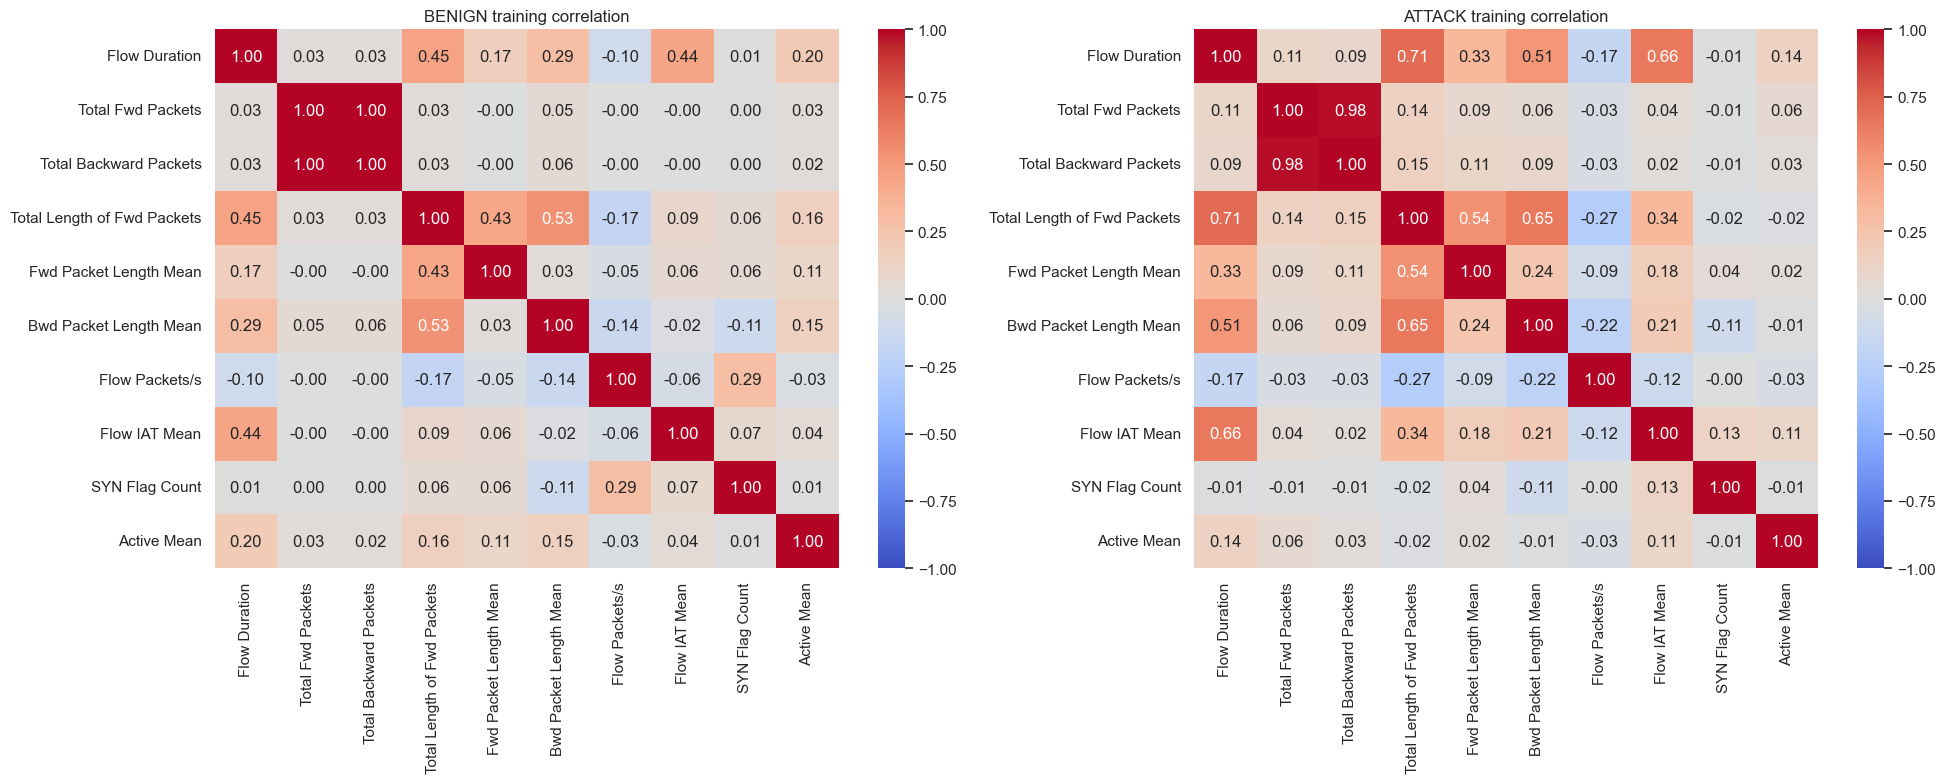

,class,feature_1,feature_2,correlation
0,BENIGN,Total Fwd Packets,Total Backward Packets,0.999077
1,ATTACK,Total Fwd Packets,Total Backward Packets,0.979449


In [21]:
# Purpose: Measure numerical correlations separately inside each training class.
# Explain: Strong within-class correlation challenges NB conditional independence; global correlation alone is insufficient.

train_numerical_df = pd.DataFrame(
    X_train_numerical,
    columns=numerical_subset_features,
)

benign_correlation = train_numerical_df.loc[
    y_train_binary == 0
].corr()
attack_correlation = train_numerical_df.loc[
    y_train_binary == 1
].corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    benign_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0],
)
axes[0].set_title("BENIGN training correlation")

sns.heatmap(
    attack_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1],
)
axes[1].set_title("ATTACK training correlation")

plt.tight_layout()
plt.show()

upper_triangle = np.triu(
    np.ones(benign_correlation.shape, dtype=bool),
    k=1,
)
strongest_pairs = []

for class_name, correlation_matrix in {
    "BENIGN": benign_correlation,
    "ATTACK": attack_correlation,
}.items():
    absolute_correlations = correlation_matrix.abs().where(
        upper_triangle
    )
    feature_1, feature_2 = absolute_correlations.stack().idxmax()
    strongest_pairs.append({
        "class": class_name,
        "feature_1": feature_1,
        "feature_2": feature_2,
        "correlation": correlation_matrix.loc[
            feature_1, feature_2
        ],
    })

strongest_correlation_pairs = pd.DataFrame(strongest_pairs)
display(strongest_correlation_pairs)

### Interpretation

The matrices measure relationships after conditioning on the class. An absolute correlation close to 1 means that knowing one feature provides substantial information about the other even when the class is already known. The strongest-pair table identifies the clearest conditional-independence violation in each class.

Gaussian Naive Bayes nevertheless multiplies these feature likelihoods as if they were independent, so it may count related evidence more than once and produce overconfident probabilities. The features are retained because the representation and models were already fixed; the correlation is documented as a model limitation rather than used for post-hoc feature selection.


- BENIGN: Total Fwd Packets vs. Total Backward Packets = 0.999
- ATTACK: Total Fwd Packets vs. Total Backward Packets = 0.979

These features remain strongly related even after conditioning on the class. Naive Bayes assumes they are independent within each class, so it effectively counts nearly the same packet-volume evidence twice. This helps explain its overconfident predictions and high log loss.

## 4.2 Destination-port frequency and additive smoothing

**Objective.** Using training data only, tabulate the most frequent destination ports in each class and identify rare ports whose class-conditional probabilities are strongly affected by additive smoothing. Define a rare port as a training level observed at most five times, and compare its unsmoothed probability with the `alpha=1` probability used by Multinomial Naive Bayes.

In [22]:
# Purpose: Inspect training port frequencies and additive smoothing for rare/unseen categories.
# Explain: Alpha assigns positive mass to every level, including other; it cannot create evidence for new services.

RARE_PORT_MAX_COUNT = 5
PORT_SMOOTHING_ALPHA = 1.0

training_port_classes = np.where(
    y_train_binary == 0, "BENIGN", "ATTACK"
)
port_count_by_class = pd.crosstab(
    pd.Series(train_port_mapped, name="port"),
    pd.Series(training_port_classes, name="class"),
).reindex(
    index=port_levels, fill_value=0
).reindex(
    columns=["BENIGN", "ATTACK"], fill_value=0
)
port_count_by_class.index.name = "port"
port_count_by_class.insert(
    0,
    "port_label",
    [
        "other" if port == OTHER_PORT else str(port)
        for port in port_count_by_class.index
    ],
)
port_count_by_class["total"] = (
    port_count_by_class["BENIGN"]
    + port_count_by_class["ATTACK"]
)

top_ports_by_class = pd.concat(
    {
        "BENIGN": port_count_by_class.nlargest(10, "BENIGN")
        .reset_index(),
        "ATTACK": port_count_by_class.nlargest(10, "ATTACK")
        .reset_index(),
    },
    names=["ranked_for_class", "rank"],
)

class_training_counts = {
    "BENIGN": int((y_train_binary == 0).sum()),
    "ATTACK": int((y_train_binary == 1).sum()),
}
number_of_port_levels = len(port_levels)
port_probability_table = port_count_by_class.copy()

for class_name in ["BENIGN", "ATTACK"]:
    class_count = class_training_counts[class_name]
    port_probability_table[
        f"{class_name.lower()}_probability_unsmoothed"
    ] = port_probability_table[class_name] / class_count
    port_probability_table[
        f"{class_name.lower()}_probability_alpha1"
    ] = (
        port_probability_table[class_name] + PORT_SMOOTHING_ALPHA
    ) / (
        class_count
        + PORT_SMOOTHING_ALPHA * number_of_port_levels
    )

rare_port_effects = port_probability_table.loc[
    port_probability_table["total"] <= RARE_PORT_MAX_COUNT
]
other_effect = rare_port_effects.loc[
    rare_port_effects.index == OTHER_PORT
]
rare_missing_from_benign = rare_port_effects.loc[
    (rare_port_effects.index != OTHER_PORT)
    & rare_port_effects["BENIGN"].eq(0)
].sort_values(["total", "ATTACK"]).head(5)
rare_missing_from_attack = rare_port_effects.loc[
    (rare_port_effects.index != OTHER_PORT)
    & rare_port_effects["ATTACK"].eq(0)
].sort_values(["total", "BENIGN"]).head(5)
representative_rare_port_effects = pd.concat(
    [
        other_effect,
        rare_missing_from_benign,
        rare_missing_from_attack,
    ]
)
representative_rare_port_effects = (
    representative_rare_port_effects.loc[
        ~representative_rare_port_effects.index.duplicated()
    ]
)

rare_port_summary = pd.Series({
    "training_port_levels_including_other": number_of_port_levels,
    "rare_observed_ports": int(
        (rare_port_effects.index != OTHER_PORT).sum()
    ),
    "rare_ports_absent_from_BENIGN": int(
        (
            (rare_port_effects.index != OTHER_PORT)
            & rare_port_effects["BENIGN"].eq(0)
        ).sum()
    ),
    "rare_ports_absent_from_ATTACK": int(
        (
            (rare_port_effects.index != OTHER_PORT)
            & rare_port_effects["ATTACK"].eq(0)
        ).sum()
    ),
    "alpha": PORT_SMOOTHING_ALPHA,
}, name="value")

print("TEN MOST FREQUENT PORTS BY CLASS")
display(top_ports_by_class)
print("RARE-PORT SUMMARY")
display(rare_port_summary.to_frame())
print("REPRESENTATIVE RARE-PORT SMOOTHING EFFECTS")
display(representative_rare_port_effects.reset_index())

TEN MOST FREQUENT PORTS BY CLASS


class                   port port_label  BENIGN  ATTACK   total
ranked_for_class rank                                          
BENIGN           0        53         53  526212      67  526279
                 1       443        443  282226      92  282318
                 2        80         80  130861  194554  325415
                 3       123        123   12824       1   12825
                 4        22         22    4078    2089    6167
                 5       389        389    3565      47    3612
                 6        88         88    3100      46    3146
                 7        21         21    2036    3698    5734
                 8       137        137    1795       0    1795
                 9       465        465    1661      44    1705
ATTACK           0        80         80  130861  194554  325415
                 1        21         21    2036    3698    5734
                 2        22         22    4078    2089    6167
                 3      8080       8080     844     816    1660
                 4       139        139    1366     112    1478
                 5       444        444      45     102     147
                 6       445        445    1130     102    1232
                 7       443        443  282226      92  282318
                 8       199        199      27      77     104
                 9     50006      50006      39      72     111

RARE-PORT SUMMARY


,value
training_port_levels_including_other,47796.0
rare_observed_ports,31247.0
rare_ports_absent_from_BENIGN,13.0
rare_ports_absent_from_ATTACK,31115.0
alpha,1.0


REPRESENTATIVE RARE-PORT SMOOTHING EFFECTS


class,port,port_label,BENIGN,ATTACK,total,benign_probability_unsmoothed,benign_probability_alpha1,attack_probability_unsmoothed,attack_probability_alpha1
0,-1,other,0,0,0,0.000000e+00,7.658809e-07,0.000000,0.000003
1,2354,2354,0,1,1,0.000000e+00,7.658809e-07,0.000004,0.000007
2,2937,2937,0,1,1,0.000000e+00,7.658809e-07,0.000004,0.000007
3,2962,2962,0,1,1,0.000000e+00,7.658809e-07,0.000004,0.000007
4,3014,3014,0,1,1,0.000000e+00,7.658809e-07,0.000004,0.000007
5,3651,3651,0,1,1,0.000000e+00,7.658809e-07,0.000004,0.000007
6,1109,1109,1,0,1,7.949821e-07,1.531762e-06,0.000000,0.000003
7,1120,1120,1,0,1,7.949821e-07,1.531762e-06,0.000000,0.000003
8,1134,1134,1,0,1,7.949821e-07,1.531762e-06,0.000000,0.000003
9,1135,1135,1,0,1,7.949821e-07,1.531762e-06,0.000000,0.000003


### Interpretation

Frequent ports have enough training observations for their class-conditional probabilities to be estimated directly. Rare ports are more sensitive to individual observations, and many are absent from one class. Without smoothing, an absent port receives probability zero for that class and can dominate the complete Naive Bayes product.

Destination Port contains strong class information: ports 53 and 443 are predominantly benign, while port 80 contains most attack traffic. However, 31,247 training ports are rare, and 31,115 of these never occur in the attack class. Additive smoothing prevents these zero counts from making a class mathematically impossible. Its relative effect is greatest for rare ports and for the explicit other category used with unseen ports.

## 4.3 Hybrid Naive Bayes contribution inspection

**Objective.** Using training data only, inspect one correct BENIGN prediction, one correct ATTACK prediction, one false positive, and one false negative from hybrid Naive Bayes. Decompose each prediction into the empirical-prior contribution, its destination-port contribution, and its five strongest numerical contributions. Positive log-evidence supports ATTACK; negative log-evidence supports BENIGN.

In [23]:
# Purpose: Explain two correct and two incorrect hybrid predictions using training examples.
# Explain: Decompose attack-versus-benign log evidence into prior, port, and numerical contributions.

HYBRID_INSPECTION_BATCH_SIZE = 100_000
required_hybrid_outcomes = [
    "correct BENIGN",
    "correct ATTACK",
    "false positive",
    "false negative",
]
selected_hybrid_positions = {}

for batch_start in range(
    0, len(y_train_binary), HYBRID_INSPECTION_BATCH_SIZE
):
    batch_end = min(
        batch_start + HYBRID_INSPECTION_BATCH_SIZE,
        len(y_train_binary),
    )
    batch_probabilities = hybrid_complete_model.predict_proba(
        X_train_complete_numeric[batch_start:batch_end],
        X_train_port[batch_start:batch_end],
    )
    batch_predictions = np.argmax(
        batch_probabilities, axis=1
    ).astype(np.int8)
    batch_targets = y_train_binary[batch_start:batch_end]
    batch_outcomes = {
        "correct BENIGN": (batch_targets == 0)
        & (batch_predictions == 0),
        "correct ATTACK": (batch_targets == 1)
        & (batch_predictions == 1),
        "false positive": (batch_targets == 0)
        & (batch_predictions == 1),
        "false negative": (batch_targets == 1)
        & (batch_predictions == 0),
    }

    for outcome_name, outcome_mask in batch_outcomes.items():
        if (
            outcome_name not in selected_hybrid_positions
            and outcome_mask.any()
        ):
            selected_hybrid_positions[outcome_name] = (
                batch_start + int(np.flatnonzero(outcome_mask)[0])
            )

    if len(selected_hybrid_positions) == len(
        required_hybrid_outcomes
    ):
        break

missing_hybrid_outcomes = set(required_hybrid_outcomes) - set(
    selected_hybrid_positions
)
if missing_hybrid_outcomes:
    raise RuntimeError(
        f"Missing training outcomes: {sorted(missing_hybrid_outcomes)}"
    )

inspection_positions = np.array([
    selected_hybrid_positions[outcome]
    for outcome in required_hybrid_outcomes
])
inspection_numerical = X_train_complete_numeric[
    inspection_positions
]
inspection_ports = X_train_port[inspection_positions]
inspection_targets = y_train_binary[inspection_positions]
inspection_probabilities = hybrid_complete_model.predict_proba(
    inspection_numerical, inspection_ports
)
inspection_predictions = np.argmax(
    inspection_probabilities, axis=1
).astype(np.int8)
inspection_row_ids = (
    model_df.loc[train_mask, "row_id"]
    .iloc[inspection_positions]
    .to_numpy()
)

hybrid_gaussian = hybrid_complete_model.gaussian_model_
hybrid_categorical = hybrid_complete_model.categorical_model_
benign_class_index = int(
    np.flatnonzero(hybrid_complete_model.classes_ == 0)[0]
)
attack_class_index = int(
    np.flatnonzero(hybrid_complete_model.classes_ == 1)[0]
)
prior_log_evidence = float(
    np.log(hybrid_gaussian.class_prior_[attack_class_index])
    - np.log(hybrid_gaussian.class_prior_[benign_class_index])
)

hybrid_example_rows = []
hybrid_numerical_contribution_rows = []

for example_index, outcome_name in enumerate(
    required_hybrid_outcomes
):
    numerical_values = inspection_numerical[example_index]
    benign_numerical_log_likelihood = -0.5 * (
        np.log(
            2.0
            * np.pi
            * hybrid_gaussian.var_[benign_class_index]
        )
        + (
            numerical_values
            - hybrid_gaussian.theta_[benign_class_index]
        ) ** 2
        / hybrid_gaussian.var_[benign_class_index]
    )
    attack_numerical_log_likelihood = -0.5 * (
        np.log(
            2.0
            * np.pi
            * hybrid_gaussian.var_[attack_class_index]
        )
        + (
            numerical_values
            - hybrid_gaussian.theta_[attack_class_index]
        ) ** 2
        / hybrid_gaussian.var_[attack_class_index]
    )
    numerical_log_evidence = (
        attack_numerical_log_likelihood
        - benign_numerical_log_likelihood
    )

    port_column = int(
        inspection_ports.getrow(example_index).indices[0]
    )
    port_value = int(train_port_mapped[inspection_positions[example_index]])
    port_label = "other" if port_value == OTHER_PORT else str(port_value)
    port_log_evidence = float(
        hybrid_categorical.feature_log_prob_[
            attack_class_index, port_column
        ]
        - hybrid_categorical.feature_log_prob_[
            benign_class_index, port_column
        ]
    )
    total_log_evidence = (
        prior_log_evidence
        + float(numerical_log_evidence.sum())
        + port_log_evidence
    )

    hybrid_example_rows.append({
        "outcome": outcome_name,
        "row_id": inspection_row_ids[example_index],
        "actual": (
            "ATTACK" if inspection_targets[example_index] else "BENIGN"
        ),
        "predicted": (
            "ATTACK"
            if inspection_predictions[example_index]
            else "BENIGN"
        ),
        "attack_probability": inspection_probabilities[
            example_index, attack_class_index
        ],
        "destination_port": port_label,
        "prior_log_evidence": prior_log_evidence,
        "port_log_evidence": port_log_evidence,
        "numerical_log_evidence": float(
            numerical_log_evidence.sum()
        ),
        "total_log_evidence": total_log_evidence,
    })

    strongest_feature_indices = np.argsort(
        np.abs(numerical_log_evidence)
    )[::-1][:5]
    for feature_index in strongest_feature_indices:
        hybrid_numerical_contribution_rows.append({
            "outcome": outcome_name,
            "feature": eligible_complete_numerical_features[
                feature_index
            ],
            "standardized_value": numerical_values[feature_index],
            "benign_log_likelihood": (
                benign_numerical_log_likelihood[feature_index]
            ),
            "attack_log_likelihood": (
                attack_numerical_log_likelihood[feature_index]
            ),
            "attack_minus_benign": numerical_log_evidence[
                feature_index
            ],
        })

hybrid_example_contributions = pd.DataFrame(
    hybrid_example_rows
).set_index("outcome")
hybrid_top_numerical_contributions = pd.DataFrame(
    hybrid_numerical_contribution_rows
).set_index(["outcome", "feature"])

print("HYBRID NB EXAMPLE CONTRIBUTIONS")
display(hybrid_example_contributions)
print("FIVE STRONGEST NUMERICAL CONTRIBUTIONS PER EXAMPLE")
display(hybrid_top_numerical_contributions)

HYBRID NB EXAMPLE CONTRIBUTIONS


,row_id,actual,predicted,attack_probability,destination_port,prior_log_evidence,port_log_evidence,numerical_log_evidence,total_log_evidence
outcome,,,,,,,,,
correct BENIGN,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::1,BENIGN,BENIGN,8.666902e-26,54865,-1.593863,-1.312903,-54.800935,-57.707701
correct ATTACK,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::18886,ATTACK,ATTACK,1.000000e+00,80,-1.593863,1.856257,186.404638,186.667033
false positive,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::6,BENIGN,ATTACK,1.000000e+00,54871,-1.593863,-0.842899,63.873380,61.436618
false negative,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::23721,ATTACK,BENIGN,0.000000e+00,80,-1.593863,1.856257,-3807.321156,-3807.058762


FIVE STRONGEST NUMERICAL CONTRIBUTIONS PER EXAMPLE


standardized_value  \
outcome        feature                                      
correct BENIGN Fwd Packets/s                     3.239397   
               Flow Packets/s                    3.057558   
               min_seg_size_forward              0.002624   
               CWE Flag Count                   -0.005632   
               Fwd URG Flags                    -0.005632   
correct ATTACK Bwd Packet Length Mean            2.519477   
               Avg Bwd Segment Size              2.519477   
               Bwd Packet Length Std             1.568556   
               Average Packet Size               3.123718   
               Packet Length Mean                3.052698   
false positive min_seg_size_forward              0.002624   
               CWE Flag Count                   -0.005632   
               Fwd URG Flags                    -0.005632   
               Fwd Header Length                 0.001434   
               RST Flag Count                   -0.016441   
false negative Bwd Packet Length Min            18.690641   
               Flow Bytes/s                      3.267507   
               Bwd Packet Length Mean            1.636135   
               Avg Bwd Segment Size              1.636135   
               min_seg_size_forward              0.002624   

                                       benign_log_likelihood  \
outcome        feature                                         
correct BENIGN Fwd Packets/s                       -5.387572   
               Flow Packets/s                      -4.918703   
               min_seg_size_forward                -1.011406   
               CWE Flag Count                      -1.011412   
               Fwd URG Flags                       -1.011412   
correct ATTACK Bwd Packet Length Mean             -18.291442   
               Avg Bwd Segment Size               -18.291442   
               Bwd Packet Length Std              -16.087485   
               Average Packet Size                -16.689404   
               Packet Length Mean                 -15.134438   
false positive min_seg_size_forward                -1.011406   
               CWE Flag Count                      -1.011412   
               Fwd URG Flags                       -1.011412   
               Fwd Header Length                   -1.011406   
               RST Flag Count                      -1.011379   
false negative Bwd Packet Length Min             -157.349695   
               Flow Bytes/s                        -5.453071   
               Bwd Packet Length Mean              -8.611555   
               Avg Bwd Segment Size                -8.611555   
               min_seg_size_forward                -1.011406   

                                       attack_log_likelihood  \
outcome        feature                                         
correct BENIGN Fwd Packets/s                      -96.254372   
               Flow Packets/s                     -29.890752   
               min_seg_size_forward                 5.988788   
               CWE Flag Count                       5.988746   
               Fwd URG Flags                        5.988746   
correct ATTACK Bwd Packet Length Mean              -1.688574   
               Avg Bwd Segment Size                -1.688574   
               Bwd Packet Length Std               -1.506894   
               Average Packet Size                 -2.139950   
               Packet Length Mean                  -2.096336   
false positive min_seg_size_forward                 5.988788   
               CWE Flag Count                       5.988746   
               Fwd URG Flags                        5.988746   
               Fwd Header Length                    5.988616   
               RST Flag Count                       5.987891   
false negative Bwd Packet Length Min            -3859.146136   
               Flow Bytes/s                      -183.153870   
               Bwd Packet Length Mean              -1.446612   
       

### Interpretation

Positive `attack_minus_benign` values support ATTACK, whereas negative values support BENIGN. The summary separates the prior, destination-port, and combined numerical evidence, making it possible to see which component dominates each correct or incorrect prediction. Incorrect predictions with very large absolute numerical evidence illustrate how Gaussian likelihoods can overwhelm useful port evidence.

The hybrid model ignores the strong dependence between `Total Fwd Packets` and `Total Backward Packets`, whose within-class correlations are 0.999 for BENIGN and 0.979 for ATTACK. It adds both likelihood contributions independently and can therefore count nearly the same traffic-volume evidence twice, contributing to overconfident posterior probabilities.

These examples clearly explain why hybrid Naive Bayes has such a large log loss.

- The class prior always contributes −1.59, favoring BENIGN because attacks are the minority.
- Port evidence is relatively small, between roughly −1.31 and +1.86.
- Numerical evidence can reach hundreds or thousands, completely overwhelming both the prior and port.


## Final test evaluation - All three representations

**Objective.** Evaluate the nine already-fitted model–representation pairs on the fixed test rows. Keep all settings selected using validation data. Predict in batches of 25,000 rows to limit temporary memory, and report balanced accuracy, attack precision, recall, F1, log loss, and confusion matrices. No models are refitted in this cell.

In [24]:
# Purpose: Score all nine frozen binary model-representation pairs on the same test rows.
# Explain: Compare classifiers within each representation; log loss measures probability quality as well as labels.

TEST_BATCH_SIZE = 25_000

y_test_binary = (
    model_df.loc[test_mask, "binary_label"]
    .eq("ATTACK")
    .astype(np.int8)
    .to_numpy()
)

test_models = {
    "A. Numerical subset": {
        "Gaussian Naive Bayes": gnb_numerical_model,
        "Logistic regression": logistic_numerical_model,
        "Decision tree": tree_numerical_model,
    },
    "B. Destination port": {
        "Multinomial Naive Bayes": mnb_port_model,
        "Logistic regression": logistic_port_model,
        "Decision tree": tree_port_model,
    },
    "C. Complete eligible set": {
        "Hybrid Naive Bayes": hybrid_complete_model,
        "Logistic regression": logistic_complete_model,
        "Decision tree": tree_complete_model,
    },
}

# Keep probabilities for the later fixed-model comparisons.
test_probabilities = {}
test_metric_rows = []
test_confusion_tables = {}

for representation, models in test_models.items():
    for model_name in models:
        test_probabilities[(representation, model_name)] = np.empty(
            (len(y_test_binary), 2), dtype=np.float64
        )

    for start in range(0, len(y_test_binary), TEST_BATCH_SIZE):
        stop = min(start + TEST_BATCH_SIZE, len(y_test_binary))

        if representation == "A. Numerical subset":
            batch_design = X_test_numerical[start:stop]
        elif representation == "B. Destination port":
            batch_design = X_test_port[start:stop]
        else:
            batch_design = hstack(
                [
                    csr_matrix(X_test_complete_numeric[start:stop]),
                    X_test_port[start:stop],
                ],
                format="csr",
                dtype=np.float32,
            )

        for model_name, fitted_model in models.items():
            if model_name == "Hybrid Naive Bayes":
                probabilities = fitted_model.predict_proba(
                    X_test_complete_numeric[start:stop],
                    X_test_port[start:stop],
                )
            else:
                probabilities = fitted_model.predict_proba(batch_design)

            test_probabilities[(representation, model_name)][
                start:stop
            ] = probabilities

    del batch_design

    for model_name in models:
        probabilities = test_probabilities[(representation, model_name)]
        predictions = np.argmax(probabilities, axis=1).astype(np.int8)
        metrics = binary_metric_row(
            model_name, y_test_binary, predictions, probabilities
        )
        metrics["representation"] = representation
        test_metric_rows.append(metrics)
        test_confusion_tables[(representation, model_name)] = pd.DataFrame(
            confusion_matrix(
                y_test_binary, predictions, labels=[0, 1]
            ),
            index=["actual BENIGN", "actual ATTACK"],
            columns=["predicted BENIGN", "predicted ATTACK"],
        )

part3_test_results = pd.DataFrame(test_metric_rows).set_index(
    ["representation", "model"]
)
part3_test_confusions = pd.concat(
    test_confusion_tables,
    names=["representation", "model", "actual_class"],
)

print("FINAL TEST RESULTS — FIXED MODELS AND SETTINGS")
display(part3_test_results)
print("TEST CONFUSION MATRICES")
display(part3_test_confusions)

FINAL TEST RESULTS — FIXED MODELS AND SETTINGS


balanced_accuracy  \
representation           model                                        
A. Numerical subset      Gaussian Naive Bayes              0.552892   
                         Logistic regression               0.786493   
                         Decision tree                     0.991230   
B. Destination port      Multinomial Naive Bayes           0.928344   
                         Logistic regression               0.928757   
                         Decision tree                     0.928757   
C. Complete eligible set Hybrid Naive Bayes                0.665305   
                         Logistic regression               0.954139   
                         Decision tree                     0.996963   

                                                  attack_precision  \
representation           model                                       
A. Numerical subset      Gaussian Naive Bayes             0.185399   
                         Logistic regression              0.978639   
                         Decision tree                    0.987199   
B. Destination port      Multinomial Naive Bayes          0.613694   
                         Logistic regression              0.613709   
                         Decision tree                    0.613709   
C. Complete eligible set Hybrid Naive Bayes               0.234093   
                         Logistic regression              0.891287   
                         Decision tree                    0.995010   

                                                  attack_recall  attack_f1  \
representation           model                                               
A. Numerical subset      Gaussian Naive Bayes          0.984491   0.312036   
                         Logistic regression           0.575538   0.724813   
                         Decision tree                 0.985054   0.986125   
B. Destination port      Multinomial Naive Bayes       0.982295   0.755430   
                         Logistic regression           0.983235   0.755719   
                         Decision tree                 0.983235   0.755719   
C. Complete eligible set Hybrid Naive Bayes            0.985818   0.378344   
                         Logistic regression           0.931354   0.910880   
                         Decision tree                 0.994940   0.994975   

                                                   log_loss  
representation           model                               
A. Numerical subset      Gaussian Naive Bayes      5.100182  
                         Logistic regression       0.233340  
                         Decision tree             0.131943  
B. Destination port      Multinomial Naive Bayes   0.211005  
                         Logistic regression       0.229865  
                         Decision tree             0.197441  
C. Complete eligible set Hybrid Naive Bayes       15.974442  
                         Logistic regression       0.069195  
                         Decision tree             0.056055

TEST CONFUSION MATRICES


predicted BENIGN  \
representation           model                   actual_class                      
A. Numerical subset      Gaussian Naive Bayes    actual BENIGN             50858   
                                                 actual ATTACK              1321   
                         Logistic regression     actual BENIGN            418227   
                                                 actual ATTACK             36154   
                         Decision tree           actual BENIGN            418209   
                                                 actual ATTACK              1273   
B. Destination port      Multinomial Naive Bayes actual BENIGN            366630   
                                                 actual ATTACK              1508   
                         Logistic regression     actual BENIGN            366583   
                                                 actual ATTACK              1428   
                         Decision tree           actual BENIGN            366583   
                                                 actual ATTACK              1428   
C. Complete eligible set Hybrid Naive Bayes      actual BENIGN            144570   
                                                 actual ATTACK              1208   
                         Logistic regression     actual BENIGN            409621   
                                                 actual ATTACK              5847   
                         Decision tree           actual BENIGN            418872   
                                                 actual ATTACK               431   

                                                                predicted ATTACK  
representation           model                   actual_class                     
A. Numerical subset      Gaussian Naive Bayes    actual BENIGN            368439  
                                                 actual ATTACK             83855  
                         Logistic regression     actual BENIGN              1070  
                                                 actual ATTACK             49022  
                         Decision tree           actual BENIGN              1088  
                                                 actual ATTACK             83903  
B. Destination port      Multinomial Naive Bayes actual BENIGN             52667  
                                                 actual ATTACK             83668  
                         Logistic regression     actual BENIGN             52714  
                                                 actual ATTACK             83748  
                         Decision tree           actual BENIGN             52714  
                                                 actual ATTACK             83748  
C. Complete eligible set Hybrid Naive Bayes      actual BENIGN            274727  
                                                 actual ATTACK             83968  
                         Logistic regression     actual BENIGN              9676  
                                                 actual ATTACK             79329  
                         Decision tree           actual BENIGN               425  
                                                 actual ATTACK             84745

### Interpretation

Compare models within each representation because they receive the same information. Balanced accuracy weights BENIGN and ATTACK recall equally; attack precision measures false-alarm burden, and attack recall measures detected attacks. Lower log loss indicates better probability predictions. Compare these test results with the earlier validation results to assess generalization, and relate the Naive Bayes results to the training-only assumption checks in Part 4. These test results are final evaluation evidence and must not be used to change features, smoothing, tree depth, regularization, or decision thresholds.

# Part 5 - Limited attack data and prior shift

## 5.1 Limited training data

**Objective.** Select a reproducible, stratified 20% subset of training rows and refit hybrid Naive Bayes, logistic regression, and the selected decision tree on identical sampled rows. Reuse the fixed feature representation, full-training preprocessing, and previously selected model settings to isolate the effect of reducing classifier-fitting data. Evaluate on the same test set and compare with the full-training results. The original fitted models are retained.

In [25]:
# Purpose: Refit complete-feature estimators on 20% of each training class.
# Explain: Keep full-training preprocessing/vocabulary and unchanged test rows; this isolates estimator-fitting size.

from sklearn.base import clone
from sklearn.model_selection import train_test_split

# Sample 20% of both classes; reuse already-fitted full-training preprocessing.
small_train_positions, _ = train_test_split(
    np.arange(len(y_train_binary)),
    train_size=0.20,
    stratify=y_train_binary,
    random_state=RANDOM_SEED,
)
small_train_positions = np.sort(small_train_positions)
y_train_small = y_train_binary[small_train_positions]

small_training_counts = pd.DataFrame({
    "full_training": [
        int((y_train_binary == 0).sum()),
        int((y_train_binary == 1).sum()),
    ],
    "smaller_training": [
        int((y_train_small == 0).sum()),
        int((y_train_small == 1).sum()),
    ],
}, index=["BENIGN", "ATTACK"])
display(small_training_counts)

small_numeric = X_train_complete_numeric[small_train_positions]
small_ports = X_train_port[small_train_positions]

hybrid_small_model = HybridNaiveBayes(
    var_smoothing=selected_hybrid_variance,
    alpha=selected_hybrid_alpha,
).fit(small_numeric, small_ports, y_train_small)

small_train_design = hstack(
    [csr_matrix(small_numeric), small_ports],
    format="csr",
    dtype=np.float32,
)

# clone copies settings, but starts with an unfitted estimator.
logistic_small_model = clone(logistic_complete_model)
logistic_small_model.fit(small_train_design, y_train_small)

tree_small_model = clone(tree_complete_model)
tree_small_model.fit(small_train_design, y_train_small)

del small_train_design, small_numeric, small_ports

small_models = {
    "Hybrid Naive Bayes": hybrid_small_model,
    "Logistic regression": logistic_small_model,
    "Decision tree": tree_small_model,
}
small_test_probabilities = {
    name: np.empty((len(y_test_binary), 2), dtype=np.float64)
    for name in small_models
}

for start in range(0, len(y_test_binary), TEST_BATCH_SIZE):
    stop = min(start + TEST_BATCH_SIZE, len(y_test_binary))
    numeric_batch = X_test_complete_numeric[start:stop]
    port_batch = X_test_port[start:stop]
    test_batch_design = hstack(
        [csr_matrix(numeric_batch), port_batch],
        format="csr",
        dtype=np.float32,
    )

    for model_name, fitted_model in small_models.items():
        if model_name == "Hybrid Naive Bayes":
            probabilities = fitted_model.predict_proba(
                numeric_batch, port_batch
            )
        else:
            probabilities = fitted_model.predict_proba(test_batch_design)
        small_test_probabilities[model_name][start:stop] = probabilities

del test_batch_design, numeric_batch, port_batch

small_test_metric_rows = []
small_test_confusion_tables = {}
for model_name, probabilities in small_test_probabilities.items():
    predictions = np.argmax(probabilities, axis=1).astype(np.int8)
    small_test_metric_rows.append(
        binary_metric_row(
            model_name, y_test_binary, predictions, probabilities
        )
    )
    small_test_confusion_tables[model_name] = pd.DataFrame(
        confusion_matrix(y_test_binary, predictions, labels=[0, 1]),
        index=["actual BENIGN", "actual ATTACK"],
        columns=["predicted BENIGN", "predicted ATTACK"],
    )

part5_small_test_results = pd.DataFrame(
    small_test_metric_rows
).set_index("model")
full_complete_test_results = part3_test_results.xs(
    "C. Complete eligible set", level="representation"
)
part5_training_size_comparison = pd.concat(
    {
        "100% training": full_complete_test_results,
        "20% training": part5_small_test_results,
    },
    names=["training_size", "model"],
)
part5_training_size_changes = (
    part5_small_test_results - full_complete_test_results
)
part5_small_test_confusions = pd.concat(
    small_test_confusion_tables,
    names=["model", "actual_class"],
)

print("TEST RESULTS BY TRAINING SIZE")
display(part5_training_size_comparison)
print("CHANGE: 20% TRAINING MINUS FULL TRAINING")
display(part5_training_size_changes)
print("SMALLER-TRAINING TEST CONFUSION MATRICES")
display(part5_small_test_confusions)

,full_training,smaller_training
BENIGN,1257890,251578
ATTACK,255527,51105


TEST RESULTS BY TRAINING SIZE


balanced_accuracy  attack_precision  \
training_size model                                                      
100% training Hybrid Naive Bayes            0.665305          0.234093   
              Logistic regression           0.954139          0.891287   
              Decision tree                 0.996963          0.995010   
20% training  Hybrid Naive Bayes            0.658143          0.230189   
              Logistic regression           0.952454          0.900611   
              Decision tree                 0.996573          0.993025   

                                   attack_recall  attack_f1   log_loss  
training_size model                                                     
100% training Hybrid Naive Bayes        0.985818   0.378344  15.974442  
              Logistic regression       0.931354   0.910880   0.069195  
              Decision tree             0.994940   0.994975   0.056055  
20% training  Hybrid Naive Bayes        0.986393   0.373270  16.967647  
              Logistic regression       0.925660   0.912964   0.071574  
              Decision tree             0.994564   0.993794   0.074265

CHANGE: 20% TRAINING MINUS FULL TRAINING


,balanced_accuracy,attack_precision,attack_recall,attack_f1,log_loss
model,,,,,
Hybrid Naive Bayes,-0.007162,-0.003904,0.000575,-0.005074,0.993205
Logistic regression,-0.001684,0.009324,-0.005694,0.002084,0.002379
Decision tree,-0.000391,-0.001985,-0.000376,-0.001181,0.018210


SMALLER-TRAINING TEST CONFUSION MATRICES


predicted BENIGN  predicted ATTACK
model               actual_class                                     
Hybrid Naive Bayes  actual BENIGN            138323            280974
                    actual ATTACK              1159             84017
Logistic regression actual BENIGN            410596              8701
                    actual ATTACK              6332             78844
Decision tree       actual BENIGN            418702               595
                    actual ATTACK               463             84713

### Interpretation

Sampling 20% of both classes reduces the number of labeled examples while approximately preserving the training class proportions. All three classifiers use the same smaller subset, fixed preprocessing, and the previously selected settings. The unchanged test set makes their results directly comparable with the full-training baseline.
- Hybrid NB: recall improves slightly, but false alarms increase from 274,727 to 280,974. Its main weakness remains its modeling assumptions, which more data did not resolve.
- Logistic regression: misses 485 additional attacks, but produces 975 fewer false alarms. Precision improves enough that F1 increases slightly, despite lower recall.
- Decision tree: produces 170 additional false alarms and misses 32 additional attacks. Its log loss increases from 0.0561 to 0.0743, so probability quality suffers more than classification accuracy.

Therefore, hybrid NB is most affected by balanced accuracy and absolute log-loss deterioration; logistic regression has the largest attack-recall decrease; the tree is most robust in classification performance.

## 5.2 Different deployment prior

**Objective.** Use the original complete-feature models trained on all training rows and assume deployment attack prevalence is 5%. Keep learned feature distributions and model parameters fixed. Replace the hybrid model's prior in log space and apply the lab's posterior correction to logistic regression and the tree. Compare predictions at threshold 0.5 and show five test flows closest to each model's original probability boundary. No fitting is required.

In [26]:
# Purpose: Adjust full-training model probabilities for an assumed 5% deployment attack prior.
# Explain: No refitting: assume stable class-conditional feature distributions and sufficiently reliable probabilities.

DEPLOYMENT_ATTACK_PRIOR = 0.05
training_attack_prior = float(y_train_binary.mean())
attack_odds_multiplier = (
    DEPLOYMENT_ATTACK_PRIOR / (1.0 - DEPLOYMENT_ATTACK_PRIOR)
) / (
    training_attack_prior / (1.0 - training_attack_prior)
)

display(pd.Series({
    "training_attack_prior": training_attack_prior,
    "deployment_attack_prior": DEPLOYMENT_ATTACK_PRIOR,
    "attack_odds_multiplier": attack_odds_multiplier,
}, name="value").to_frame())

prior_shift_probabilities = {}
full_complete_models = {
    "Hybrid Naive Bayes": hybrid_complete_model,
    "Logistic regression": logistic_complete_model,
    "Decision tree": tree_complete_model,
}

# Replace the hybrid prior in log space without modifying the fitted model.
hybrid_prior_adjustment = (
    np.log([1.0 - DEPLOYMENT_ATTACK_PRIOR, DEPLOYMENT_ATTACK_PRIOR])
    - np.log(hybrid_complete_model.gaussian_model_.class_prior_)
)
hybrid_deployment_probability = np.empty(
    len(y_test_binary), dtype=np.float64
)

for start in range(0, len(y_test_binary), TEST_BATCH_SIZE):
    stop = min(start + TEST_BATCH_SIZE, len(y_test_binary))
    deployment_scores = hybrid_complete_model._joint_log_likelihood(
        X_test_complete_numeric[start:stop],
        X_test_port[start:stop],
    )
    deployment_scores += hybrid_prior_adjustment
    hybrid_deployment_probability[start:stop] = np.exp(
        deployment_scores[:, 1]
        - logsumexp(deployment_scores, axis=1)
    )

prior_shift_probabilities["Hybrid Naive Bayes"] = (
    hybrid_deployment_probability
)

# Apply the lab's posterior correction to the discriminative models.
for model_name in ["Logistic regression", "Decision tree"]:
    # Select the attack-probability column from each saved binary model.
    original_probability = test_probabilities[
        ("C. Complete eligible set", model_name)
    ][:, 1]
    # Reweight attack support by deployment prior / training prior.
    attack_term = (
        DEPLOYMENT_ATTACK_PRIOR / training_attack_prior
    ) * original_probability
    # Reweight benign support by its corresponding prior ratio.
    benign_term = (
        (1.0 - DEPLOYMENT_ATTACK_PRIOR)
        / (1.0 - training_attack_prior)
    ) * (1.0 - original_probability)
    # Normalize the two terms to obtain the new attack posterior.
    prior_shift_probabilities[model_name] = attack_term / (
        attack_term + benign_term
    )

# Keep provenance for identifying the example flows inspected later.
test_row_ids = model_df.loc[test_mask, "row_id"].to_numpy()
prior_shift_summary_rows = []
near_boundary_tables = {}

for model_name in full_complete_models:
    original_probability = test_probabilities[
        ("C. Complete eligible set", model_name)
    ][:, 1]
    adjusted_probability = prior_shift_probabilities[model_name]

    for setting, probabilities in {
        "Training prior": original_probability,
        "5% deployment prior": adjusted_probability,
    }.items():
        # Match the earlier argmax convention: ties predict BENIGN.
        predictions = (probabilities > 0.5).astype(np.int8)
        tn, fp, fn, tp = confusion_matrix(
            y_test_binary, predictions, labels=[0, 1]
        ).ravel()
        prior_shift_summary_rows.append({
            "model": model_name,
            "prior_setting": setting,
            "predicted_attacks": int(tp + fp),
            "false_alarms": int(fp),
            "missed_attacks": int(fn),
            "attack_recall": tp / (tp + fn),
            "false_positive_rate": fp / (tn + fp),
        })

    # Stable ordering makes ties reproducible, including tied tree leaves.
    boundary_positions = np.argsort(
        np.abs(original_probability - 0.5), kind="stable"
    )[:5]
    near_boundary_tables[model_name] = pd.DataFrame({
        "row_id": test_row_ids[boundary_positions],
        "actual": np.where(
            y_test_binary[boundary_positions] == 1, "ATTACK", "BENIGN"
        ),
        "attack_probability_before": original_probability[
            boundary_positions
        ],
        "attack_probability_after": adjusted_probability[
            boundary_positions
        ],
        "predicted_before": np.where(
            original_probability[boundary_positions] > 0.5,
            "ATTACK", "BENIGN",
        ),
        "predicted_after": np.where(
            adjusted_probability[boundary_positions] > 0.5,
            "ATTACK", "BENIGN",
        ),
    })

part5_prior_shift_summary = pd.DataFrame(
    prior_shift_summary_rows
).set_index(["model", "prior_setting"])
part5_near_boundary_flows = pd.concat(
    near_boundary_tables, names=["model", "example"]
)

print("PRIOR ADJUSTMENT ON THE ORIGINAL TEST ROWS — THRESHOLD 0.5")
display(part5_prior_shift_summary)
print("FIVE FLOWS CLOSEST TO EACH MODEL'S ORIGINAL BOUNDARY")
display(part5_near_boundary_flows)

,value
training_attack_prior,0.168841
deployment_attack_prior,0.050000
attack_odds_multiplier,0.259091


PRIOR ADJUSTMENT ON THE ORIGINAL TEST ROWS — THRESHOLD 0.5


predicted_attacks  false_alarms  \
model               prior_setting                                          
Hybrid Naive Bayes  Training prior                  358695        274727   
                    5% deployment prior             357262        273297   
Logistic regression Training prior                   89005          9676   
                    5% deployment prior              60957           351   
Decision tree       Training prior                   85170           425   
                    5% deployment prior              85170           425   

                                         missed_attacks  attack_recall  \
model               prior_setting                                        
Hybrid Naive Bayes  Training prior                 1208       0.985818   
                    5% deployment prior            1211       0.985782   
Logistic regression Training prior                 5847       0.931354   
                    5% deployment prior           24570       0.711538   
Decision tree       Training prior                  431       0.994940   
                    5% deployment prior             431       0.994940   

                                         false_positive_rate  
model               prior_setting                             
Hybrid Naive Bayes  Training prior                  0.655209  
                    5% deployment prior             0.651798  
Logistic regression Training prior                  0.023077  
                    5% deployment prior             0.000837  
Decision tree       Training prior                  0.001014  
                    5% deployment prior             0.001014

FIVE FLOWS CLOSEST TO EACH MODEL'S ORIGINAL BOUNDARY


row_id  \
model               example                                                                        
Hybrid Naive Bayes  0                                  Monday-WorkingHours.pcap_ISCX.csv::214147   
                    1                               Wednesday-workingHours.pcap_ISCX.csv::509162   
                    2                               Wednesday-workingHours.pcap_ISCX.csv::538889   
                    3                                 Tuesday-WorkingHours.pcap_ISCX.csv::306054   
                    4                               Wednesday-workingHours.pcap_ISCX.csv::407492   
Logistic regression 0                                   Tuesday-WorkingHours.pcap_ISCX.csv::4184   
                    1                    Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv::43419   
                    2        Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv::116563   
                    3          Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv::9430   
                    4             Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv::138513   
Decision tree       0                Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv::40379   
                    1                Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv::47748   
                    2                Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv::87982   
                    3                Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv::89388   
                    4                Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv::89687   

                             actual  attack_probability_before  \
model               example                                      
Hybrid Naive Bayes  0        BENIGN                   0.498979   
                    1        BENIGN                   0.501887   
                    2        BENIGN                   0.497887   
                    3        BENIGN                   0.497740   
                    4        BENIGN                   0.497379   
Logistic regression 0        BENIGN                   0.499976   
                    1        ATTACK                   0.500037   
                    2        BENIGN                   0.499950   
                    3        BENIGN                   0.499945   
                    4        BENIGN                   0.500067   
Decision tree       0        ATTACK                   0.500000   
                    1        BENIGN                   0.500000   
                    2        ATTACK                   0.500000   
                    3        ATTACK                   0.500000   
                    4        ATTACK                   0.500000   

                             attack_probability_after predicted_before  \
model               example                                              
Hybrid Naive Bayes  0                        0.205110           BENIGN   
                    1                        0.207012           ATTACK   
                    2                        0.204398           BENIGN   
                    3                        0.204303           BENIGN   
                    4                        0.204068           BENIGN   
Logistic regression 0                        0.205761           BENIGN   
                    1                        0.205801           ATTACK   
                    2                        0.205744           BENIGN   
                    3                        0.205740           BENIGN   
                    4                        0.205820           ATTACK   
Decision tree       0                        0.205776           BENIGN   
                    1                        0.205776           BENIGN   
                    2                        0.205776           BENIGN   
                    3                        0.205776           BENIGN   
                    4                        0.205776           BENIGN   

       

### Interpretation

Reducing the assumed attack prior from about 16.9% to 5% multiplies attack odds by about 0.26. Ambiguous flows therefore receive lower attack probabilities, typically reducing false alarms while increasing missed attacks at the fixed 0.5 threshold. The five examples per model are selected by proximity to the original 0.5 boundary; tied tree probabilities may give identical before-and-after values.

it does not create a test population containing 5% attacks. Prior correction assumes that class-conditional feature distributions remain unchanged and that the original posterior estimates are reliable. Exact tree probabilities of 0 and 1 remain unchanged by the correction, illustrating a limitation of coarse leaf probabilities.

A prior change describes a different frequency of attacks and changes the posterior probabilities. A decision-threshold change describes different costs of false alarms and missed attacks and changes the action taken from those probabilities. Although either can move a classification boundary, they answer different questions. This experiment changes the prior and keeps the threshold fixed; test results are not used to tune either quantity.

# Part 6 - Multiclass classification

## 6.1 Category eligibility

**Objective.** Retain BENIGN as a category and keep attack categories with at least 100 training, 20 validation, and 20 test examples, as specified by the lab. Report retained and excluded categories with their counts, then define row filters aligned with the existing partition feature matrices. These filters apply only to the multiclass comparison; the binary experiments and fixed partition assignments remain unchanged.

In [27]:
# Purpose: Select multiclass categories meeting the specified minimum partition counts.
# Explain: Exclude ineligible categories only from this comparison; keep all attacks in binary detection.

multiclass_eligibility = multiclass_counts.copy()
multiclass_eligibility["eligible"] = (
    (multiclass_eligibility["train"] >= 100)
    & (multiclass_eligibility["validation"] >= 20)
    & (multiclass_eligibility["test"] >= 20)
)
# BENIGN remains one of the multiclass categories.
multiclass_eligibility.loc["BENIGN", "eligible"] = True

retained_multiclass_labels = multiclass_eligibility.index[
    multiclass_eligibility["eligible"]
].tolist()
excluded_multiclass_labels = multiclass_eligibility.index[
    ~multiclass_eligibility["eligible"]
].tolist()

print("RETAINED MULTICLASS CATEGORIES")
display(multiclass_eligibility.loc[retained_multiclass_labels])
print("EXCLUDED FROM MULTICLASS ONLY")
display(multiclass_eligibility.loc[excluded_multiclass_labels])

# These filters align with each partition's existing feature matrices.
train_multiclass_labels = model_df.loc[
    train_mask, "Label"
].to_numpy()
validation_multiclass_labels = model_df.loc[
    validation_mask, "Label"
].to_numpy()
test_multiclass_labels = model_df.loc[
    test_mask, "Label"
].to_numpy()

multiclass_train_keep = np.isin(
    train_multiclass_labels, retained_multiclass_labels
)
multiclass_validation_keep = np.isin(
    validation_multiclass_labels, retained_multiclass_labels
)
multiclass_test_keep = np.isin(
    test_multiclass_labels, retained_multiclass_labels
)

y_train_multiclass = train_multiclass_labels[multiclass_train_keep]
y_validation_multiclass = validation_multiclass_labels[
    multiclass_validation_keep
]
y_test_multiclass = test_multiclass_labels[multiclass_test_keep]

print("RETAINED ROWS FOR THE MULTICLASS COMPARISON")
display(pd.Series({
    "train": len(y_train_multiclass),
    "validation": len(y_validation_multiclass),
    "test": len(y_test_multiclass),
}, name="rows").to_frame())

RETAINED MULTICLASS CATEGORIES


partition,train,validation,test,eligible
Label,,,,
BENIGN,1257890,419297,419297,True
Bot,1172,391,390,True
DDoS,76809,25603,25604,True
DoS GoldenEye,6172,2057,2057,True
DoS Hulk,103709,34570,34570,True
DoS Slowhttptest,3137,1045,1046,True
DoS slowloris,3231,1077,1077,True
FTP-Patator,3560,1186,1187,True
PortScan,54491,18164,18164,True


EXCLUDED FROM MULTICLASS ONLY


partition,train,validation,test,eligible
Label,,,,
Heartbleed,7,2,2,False
Infiltration,22,7,7,False
Web Attack - Sql Injection,13,4,4,False


RETAINED ROWS FOR THE MULTICLASS COMPARISON


,rows
train,1513375
validation,504459
test,504460


### Interpretation

The tables show which traffic categories meet the lab's minimum sample counts and which are excluded from multiclass evaluation. BENIGN remains a separate class rather than being combined with any attack category. Excluded attack categories are still present in the binary experiments.

The retained rows preserve their original training, validation, and test assignments. The same filters will be used for every multiclass model, both without and with Destination Port, so comparisons use identical examples. Checking test counts here is an explicit eligibility requirement of the lab; test performance will not be used for model selection.

## 6.2 Multiclass models without Destination Port

**Objective.** Fit Gaussian Naive Bayes, logistic regression, and a decision tree on all 68 eligible numerical features and the retained multiclass training rows. Reuse the fixed training-derived preprocessing. Start NB at standard variance smoothing, start logistic regression without regularization with the established L2 fallback, and select tree depth from the original candidates using multiclass validation balanced accuracy. The reusable fitting function applies identical rules to both feature sets.

In [28]:
# Purpose: Fit multiclass models without port and select tree depth on validation.
# Explain: Macro-F1 and class recalls reveal minority failures; inspect any logistic regularization fallback.

from sklearn.metrics import ConfusionMatrixDisplay

# Fit both representations with the same declared stability and depth rules.
def fit_multiclass_discriminative(train_design, validation_design):
    fitted_logistic = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=LOGISTIC_MAX_ITERATIONS,
        random_state=RANDOM_SEED,
    )
    with warnings.catch_warnings(record=True) as initial_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        fitted_logistic.fit(train_design, y_train_multiclass)

    initial_warning_count = sum(
        issubclass(item.category, ConvergenceWarning)
        for item in initial_warnings
    )
    initial_iterations = int(fitted_logistic.n_iter_.max())
    initial_max_coefficient = float(np.abs(fitted_logistic.coef_).max())
    needs_l2 = (
        initial_warning_count > 0
        or initial_iterations >= LOGISTIC_MAX_ITERATIONS
        or initial_max_coefficient > LARGE_COEFFICIENT_THRESHOLD
    )
    final_warning_count = initial_warning_count
    if needs_l2:
        fitted_logistic = LogisticRegression(
            penalty="l2", C=1.0, solver="lbfgs",
            max_iter=LOGISTIC_MAX_ITERATIONS,
            random_state=RANDOM_SEED,
        )
        with warnings.catch_warnings(record=True) as final_warnings:
            warnings.simplefilter("always", ConvergenceWarning)
            fitted_logistic.fit(train_design, y_train_multiclass)
        final_warning_count = sum(
            issubclass(item.category, ConvergenceWarning)
            for item in final_warnings
        )

    logistic_diagnostics = pd.Series({
        "initial_convergence_warnings": initial_warning_count,
        "initial_iterations": initial_iterations,
        "initial_max_absolute_coefficient": initial_max_coefficient,
        "selected_setting": "L2, C=1.0" if needs_l2 else "no regularization",
        "final_iterations": int(fitted_logistic.n_iter_.max()),
        "final_convergence_warnings": final_warning_count,
    }, name="value")

    best_score = -np.inf
    depth_rows = []
    for depth in TREE_DEPTH_CANDIDATES:
        candidate = DecisionTreeClassifier(
            max_depth=depth, random_state=RANDOM_SEED
        )
        candidate.fit(train_design, y_train_multiclass)
        predictions = candidate.predict(validation_design)
        score = balanced_accuracy_score(
            y_validation_multiclass, predictions
        )
        depth_rows.append({
            "max_depth": "unlimited" if depth is None else str(depth),
            "validation_balanced_accuracy": score,
            "validation_macro_f1": f1_score(
                y_validation_multiclass, predictions,
                labels=retained_multiclass_labels,
                average="macro", zero_division=0,
            ),
        })
        if score > best_score:
            best_score = score
            fitted_tree = candidate

    return (
        fitted_logistic, fitted_tree,
        logistic_diagnostics, pd.DataFrame(depth_rows),
    )


# Standard NB settings are fixed before examining multiclass test results.
MULTICLASS_VAR_SMOOTHING = 1e-9
MULTICLASS_ALPHA = 1.0

multiclass_numeric_train = X_train_complete_numeric[multiclass_train_keep]
multiclass_numeric_validation = X_validation_complete_numeric[
    multiclass_validation_keep
]

gnb_multiclass_model = GaussianNB(
    var_smoothing=MULTICLASS_VAR_SMOOTHING
).fit(multiclass_numeric_train, y_train_multiclass)

(
    logistic_multiclass_numeric_model,
    tree_multiclass_numeric_model,
    multiclass_numeric_logistic_diagnostics,
    multiclass_numeric_tree_tuning,
) = fit_multiclass_discriminative(
    multiclass_numeric_train, multiclass_numeric_validation
)

print("NUMERICAL-ONLY LOGISTIC STABILITY CHECK")
display(multiclass_numeric_logistic_diagnostics.to_frame())
print("NUMERICAL-ONLY TREE DEPTH SELECTION")
display(multiclass_numeric_tree_tuning)
print("Selected depth:", tree_multiclass_numeric_model.max_depth)
print("First two levels of the numerical-only tree")
print(export_text(
    tree_multiclass_numeric_model,
    feature_names=eligible_complete_numerical_features,
    max_depth=2,
))


NUMERICAL-ONLY LOGISTIC STABILITY CHECK


,value
initial_convergence_warnings,1
initial_iterations,500
initial_max_absolute_coefficient,91.348412
selected_setting,"L2, C=1.0"
final_iterations,334
final_convergence_warnings,0


NUMERICAL-ONLY TREE DEPTH SELECTION


,max_depth,validation_balanced_accuracy,validation_macro_f1
0,3,0.330797,0.336820
1,5,0.431029,0.464458
2,10,0.751039,0.771156
3,unlimited,0.908783,0.906959


Selected depth: None
First two levels of the numerical-only tree
|--- Bwd Packet Length Std <= 1.27
|   |--- Average Packet Size <= -0.59
|   |   |--- Packet Length Std <= -0.50
|   |   |   |--- truncated branch of depth 46
|   |   |--- Packet Length Std >  -0.50
|   |   |   |--- truncated branch of depth 28
|   |--- Average Packet Size >  -0.59
|   |   |--- Active Std <= 10.93
|   |   |   |--- truncated branch of depth 37
|   |   |--- Active Std >  10.93
|   |   |   |--- truncated branch of depth 6
|--- Bwd Packet Length Std >  1.27
|   |--- Fwd Packet Length Max <= -0.25
|   |   |--- Fwd Packet Length Max <= -0.28
|   |   |   |--- class: PortScan
|   |   |--- Fwd Packet Length Max >  -0.28
|   |   |   |--- class: DDoS
|   |--- Fwd Packet Length Max >  -0.25
|   |   |--- Subflow Bwd Bytes <= -0.00
|   |   |   |--- truncated branch of depth 7
|   |   |--- Subflow Bwd Bytes >  -0.00
|   |   |   |--- truncated branch of depth 7



### Interpretation

The validation table selects tree depth using the average recall across the retained classes, giving rare classes the same weight as BENIGN. The logistic diagnostics document convergence and any L2 fallback. A nonzero final convergence-warning count means optimization remains unfinished and must be addressed before interpreting the final comparison. These models use every eligible numerical feature, rather than the earlier 10-feature subset. Test performance has not been used to select settings.

## 6.3 Multiclass models with Destination Port

**Objective.** Fit hybrid Naive Bayes, logistic regression, and a decision tree on the exact same retained rows, adding the existing categorical port representation to the same numerical features. Keep the same standard Gaussian variance smoothing; use alpha=1 for port probabilities. Select tree depth using multiclass validation balanced accuracy, then release the temporary training and validation designs.

In [29]:
# Purpose: Fit multiclass models with port using the same eligible rows and numerical features.
# Explain: Model-family/regularization differences qualify how much gain can be attributed to port alone.

multiclass_port_train = X_train_port[multiclass_train_keep]
multiclass_port_validation = X_validation_port[
    multiclass_validation_keep
]

hybrid_multiclass_model = HybridNaiveBayes(
    var_smoothing=MULTICLASS_VAR_SMOOTHING,
    alpha=MULTICLASS_ALPHA,
).fit(
    multiclass_numeric_train,
    multiclass_port_train,
    y_train_multiclass,
)

multiclass_complete_train = hstack(
    [csr_matrix(multiclass_numeric_train), multiclass_port_train],
    format="csr", dtype=np.float32,
)
multiclass_complete_validation = hstack(
    [csr_matrix(multiclass_numeric_validation), multiclass_port_validation],
    format="csr", dtype=np.float32,
)

(
    logistic_multiclass_complete_model,
    tree_multiclass_complete_model,
    multiclass_complete_logistic_diagnostics,
    multiclass_complete_tree_tuning,
) = fit_multiclass_discriminative(
    multiclass_complete_train, multiclass_complete_validation
)

print("WITH-PORT LOGISTIC STABILITY CHECK")
display(multiclass_complete_logistic_diagnostics.to_frame())
print("WITH-PORT TREE DEPTH SELECTION")
display(multiclass_complete_tree_tuning)
print("Selected depth:", tree_multiclass_complete_model.max_depth)
print("First two levels of the with-port tree")
print(export_text(
    tree_multiclass_complete_model,
    feature_names=eligible_complete_numerical_features + list(port_feature_names),
    max_depth=2,
))
print("Fixed NB settings:", {
    "var_smoothing": MULTICLASS_VAR_SMOOTHING,
    "categorical_alpha": MULTICLASS_ALPHA,
})

del multiclass_complete_train, multiclass_complete_validation
del multiclass_numeric_train, multiclass_numeric_validation
del multiclass_port_train, multiclass_port_validation


WITH-PORT LOGISTIC STABILITY CHECK


,value
initial_convergence_warnings,0
initial_iterations,214
initial_max_absolute_coefficient,27.890385
selected_setting,no regularization
final_iterations,214
final_convergence_warnings,0


WITH-PORT TREE DEPTH SELECTION


,max_depth,validation_balanced_accuracy,validation_macro_f1
0,3,0.412962,0.403415
1,5,0.540550,0.553621
2,10,0.740694,0.771032
3,unlimited,0.907341,0.905992


Selected depth: None
First two levels of the with-port tree
|--- Bwd Packet Length Std <= 1.27
|   |--- Average Packet Size <= -0.59
|   |   |--- Packet Length Std <= -0.50
|   |   |   |--- truncated branch of depth 48
|   |   |--- Packet Length Std >  -0.50
|   |   |   |--- truncated branch of depth 133
|   |--- Average Packet Size >  -0.59
|   |   |--- Destination Port=21 <= 0.50
|   |   |   |--- truncated branch of depth 122
|   |   |--- Destination Port=21 >  0.50
|   |   |   |--- truncated branch of depth 3
|--- Bwd Packet Length Std >  1.27
|   |--- Fwd Packet Length Max <= -0.25
|   |   |--- min_seg_size_forward <= 0.00
|   |   |   |--- class: DDoS
|   |   |--- min_seg_size_forward >  0.00
|   |   |   |--- class: PortScan
|   |--- Fwd Packet Length Max >  -0.25
|   |   |--- Subflow Bwd Bytes <= -0.00
|   |   |   |--- truncated branch of depth 7
|   |   |--- Subflow Bwd Bytes >  -0.00
|   |   |   |--- truncated branch of depth 7

Fixed NB settings: {'var_smoothing': 1e-09, 'categ

### Interpretation

This feature set adds service identity to the same numerical behavior. Gaussian and hybrid Naive Bayes share the same numerical model and smoothing; hybrid adds the smoothed port likelihood and includes the class prior only once. Logistic regression and the tree receive numerical features plus one-hot ports. Both comparisons reuse the original training-defined port levels and other category. Review optimizer diagnostics before running the final test comparison.

## 6.4 Multiclass test comparison and port contribution

**Objective.** Evaluate all six fixed models on identical retained test rows in batches. Report macro-F1, class-wise recall, and confusion matrices. Calculate the recall change from adding Destination Port and list the three attack categories most affected for each classifier family.

MULTICLASS TEST RESULTS


macro_f1  balanced_accuracy
representation model                                           
Without port   Naive Bayes          0.358691           0.744631
               Logistic regression  0.690597           0.667992
               Decision tree        0.912193           0.913557
With port      Naive Bayes          0.345947           0.746400
               Logistic regression  0.769502           0.750272
               Decision tree        0.909252           0.910577

CLASS-WISE RECALL


representation           Without port                                    \
model                     Naive Bayes Logistic regression Decision tree   
class                                                                     
BENIGN                       0.111539            0.994996      0.999032   
Bot                          0.643590            0.020513      0.802564   
DDoS                         0.953132            0.998945      0.999805   
DoS GoldenEye                0.991249            0.855129      0.993680   
DoS Hulk                     0.934452            0.925513      0.998207   
DoS Slowhttptest             0.653920            0.784895      0.957935   
DoS slowloris                0.636026            0.863510      0.985144   
FTP-Patator                  0.996630            0.667228      1.000000   
PortScan                     0.983319            0.992127      0.999174   
SSH-Patator                  0.923913            0.913043      0.996894   
Web Attack - Brute Force     0.146259            0.000000      0.768707   
Web Attack - XSS             0.961538            0.000000      0.461538   

representation             With port                                    
model                    Naive Bayes Logistic regression Decision tree  
class                                                                   
BENIGN                      0.114318            0.998605      0.999077  
Bot                         0.643590            0.392308      0.748718  
DDoS                        0.957507            0.999024      0.999844  
DoS GoldenEye               0.991249            0.893534      0.994652  
DoS Hulk                    0.934886            0.955019      0.998264  
DoS Slowhttptest            0.653920            0.912046      0.991396  
DoS slowloris               0.636955            0.927577      0.988858  
FTP-Patator                 0.996630            0.997473      0.999158  
PortScan                    0.983319            0.992898      0.985961  
SSH-Patator                 0.923913            0.934783      0.998447  
Web Attack - Brute Force    0.166667            0.000000      0.768707  
Web Attack - XSS            0.953846            0.000000      0.453846

RECALL CHANGE FROM ADDING PORT — POSITIVE MEANS IMPROVEMENT


model,Naive Bayes,Logistic regression,Decision tree
class,,,
BENIGN,0.002778,0.003608,0.000045
Bot,0.000000,0.371795,-0.053846
DDoS,0.004374,0.000078,0.000039
DoS GoldenEye,0.000000,0.038405,0.000972
DoS Hulk,0.000434,0.029505,0.000058
DoS Slowhttptest,0.000000,0.127151,0.033461
DoS slowloris,0.000929,0.064067,0.003714
FTP-Patator,0.000000,0.330244,-0.000842
PortScan,0.000000,0.000771,-0.013213


... (2 outputs left out)

LARGEST ATTACK-RECALL CHANGES: Logistic regression


,recall_change
class,
Bot,0.371795
FTP-Patator,0.330244
DoS Slowhttptest,0.127151


LARGEST ATTACK-RECALL CHANGES: Decision tree


,recall_change
class,
Bot,-0.053846
DoS Slowhttptest,0.033461
PortScan,-0.013213


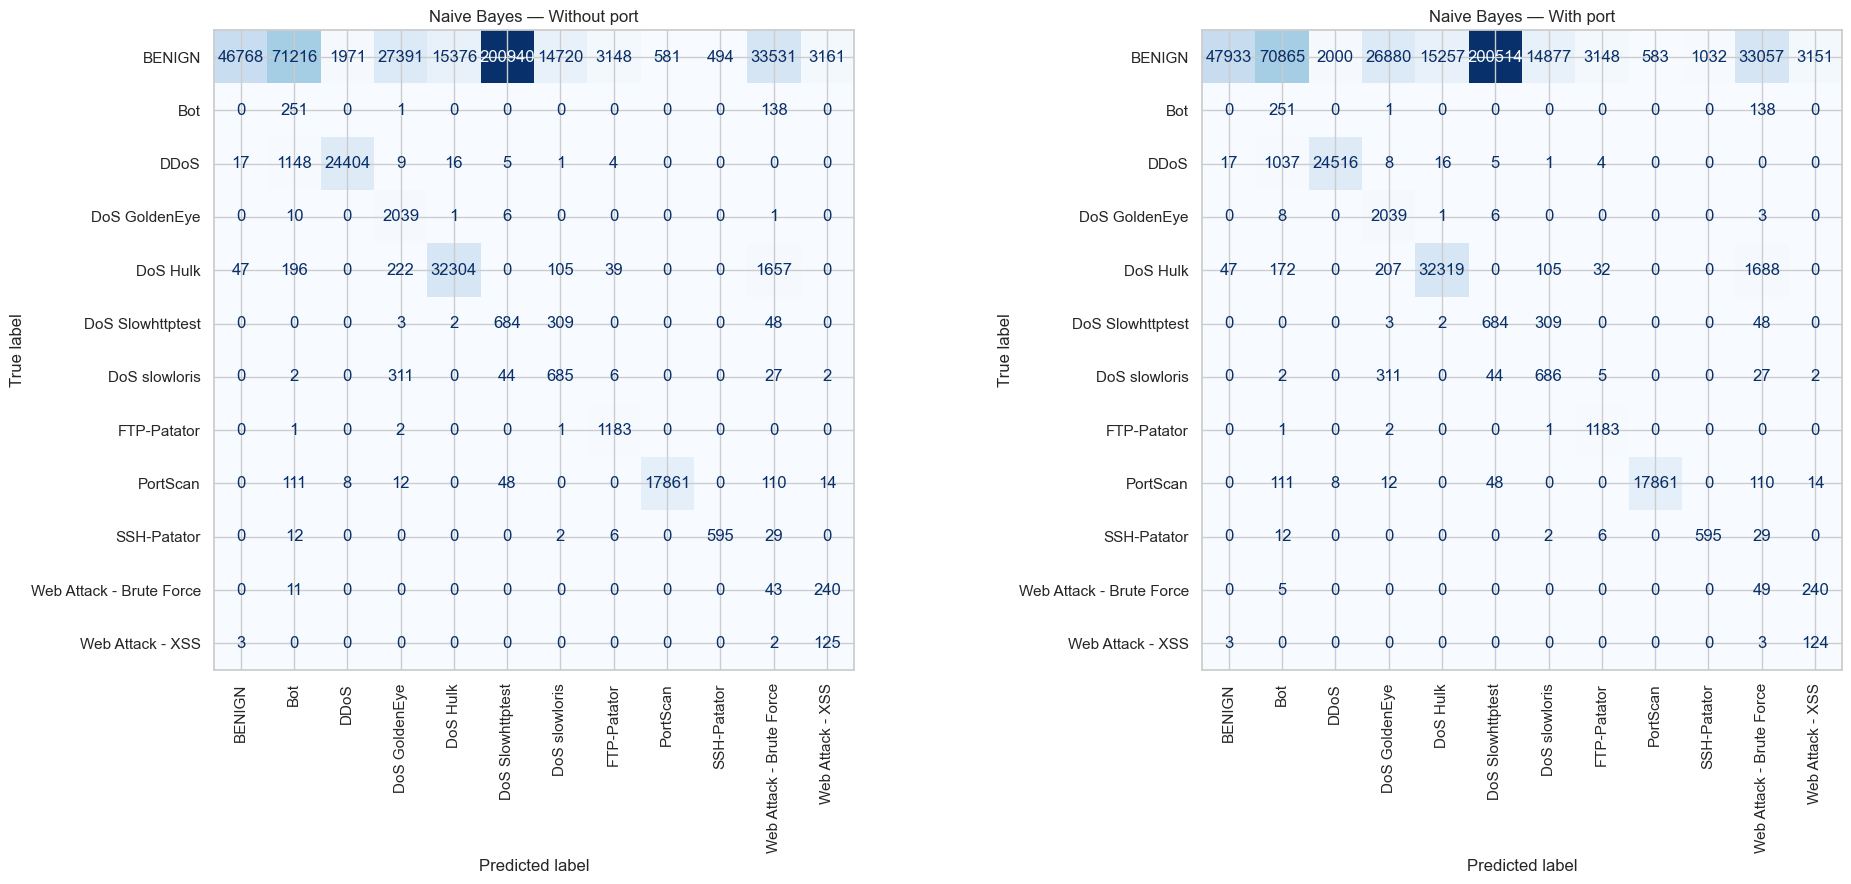

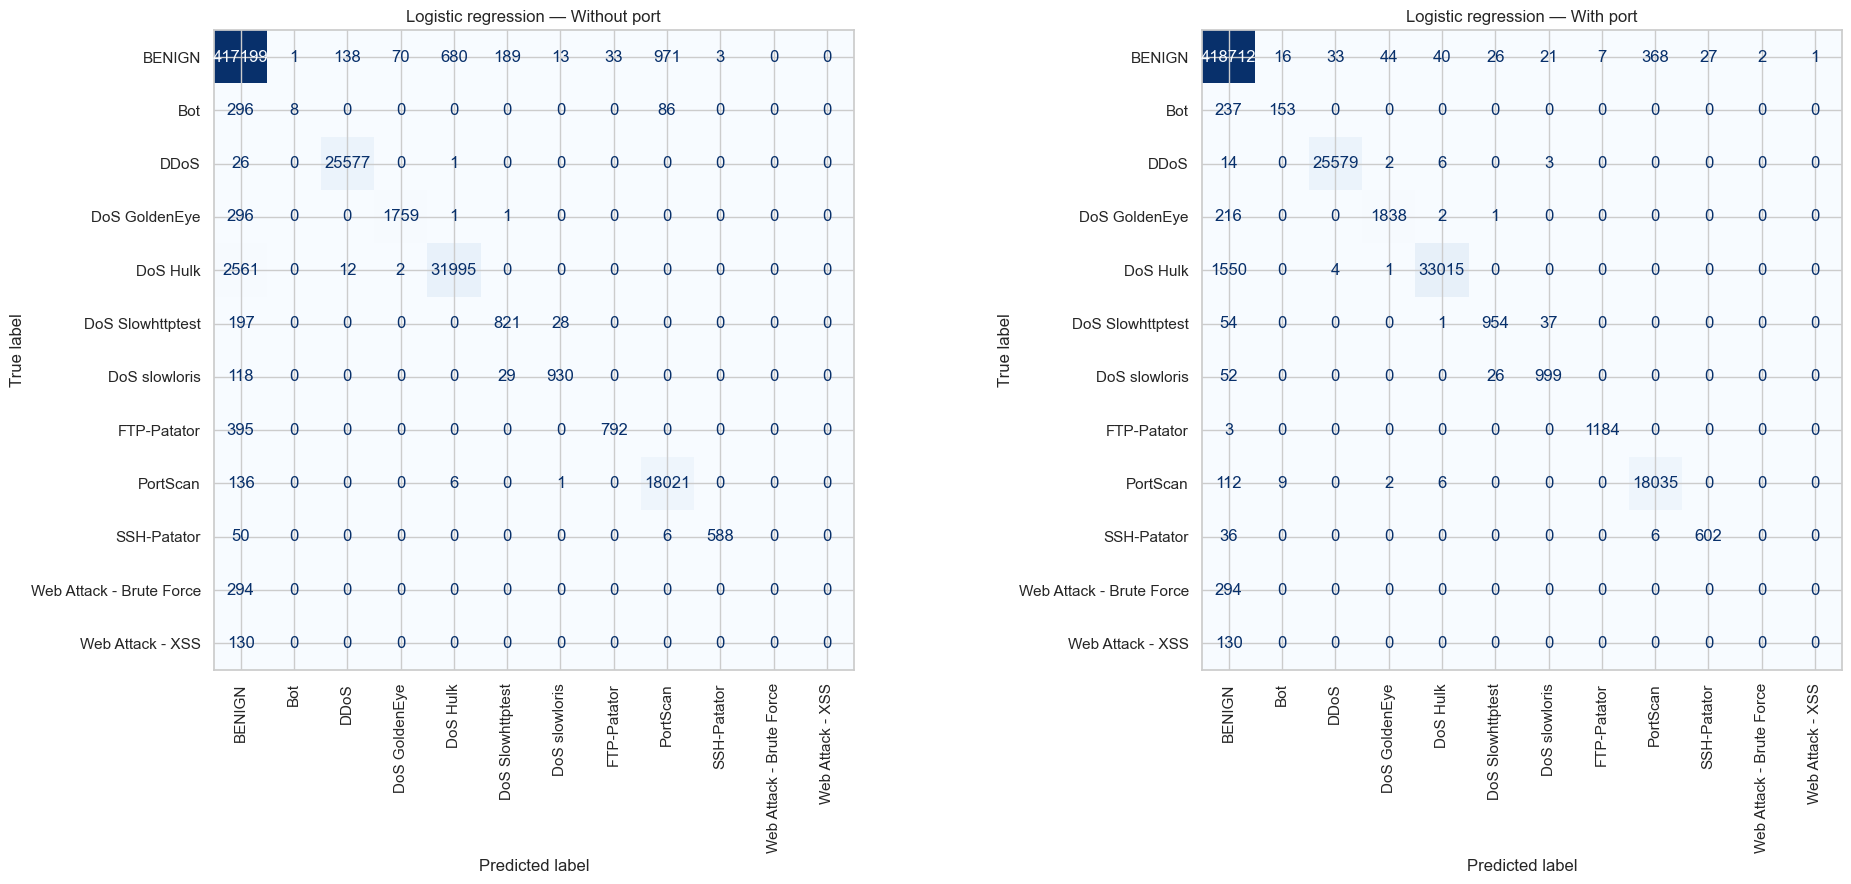

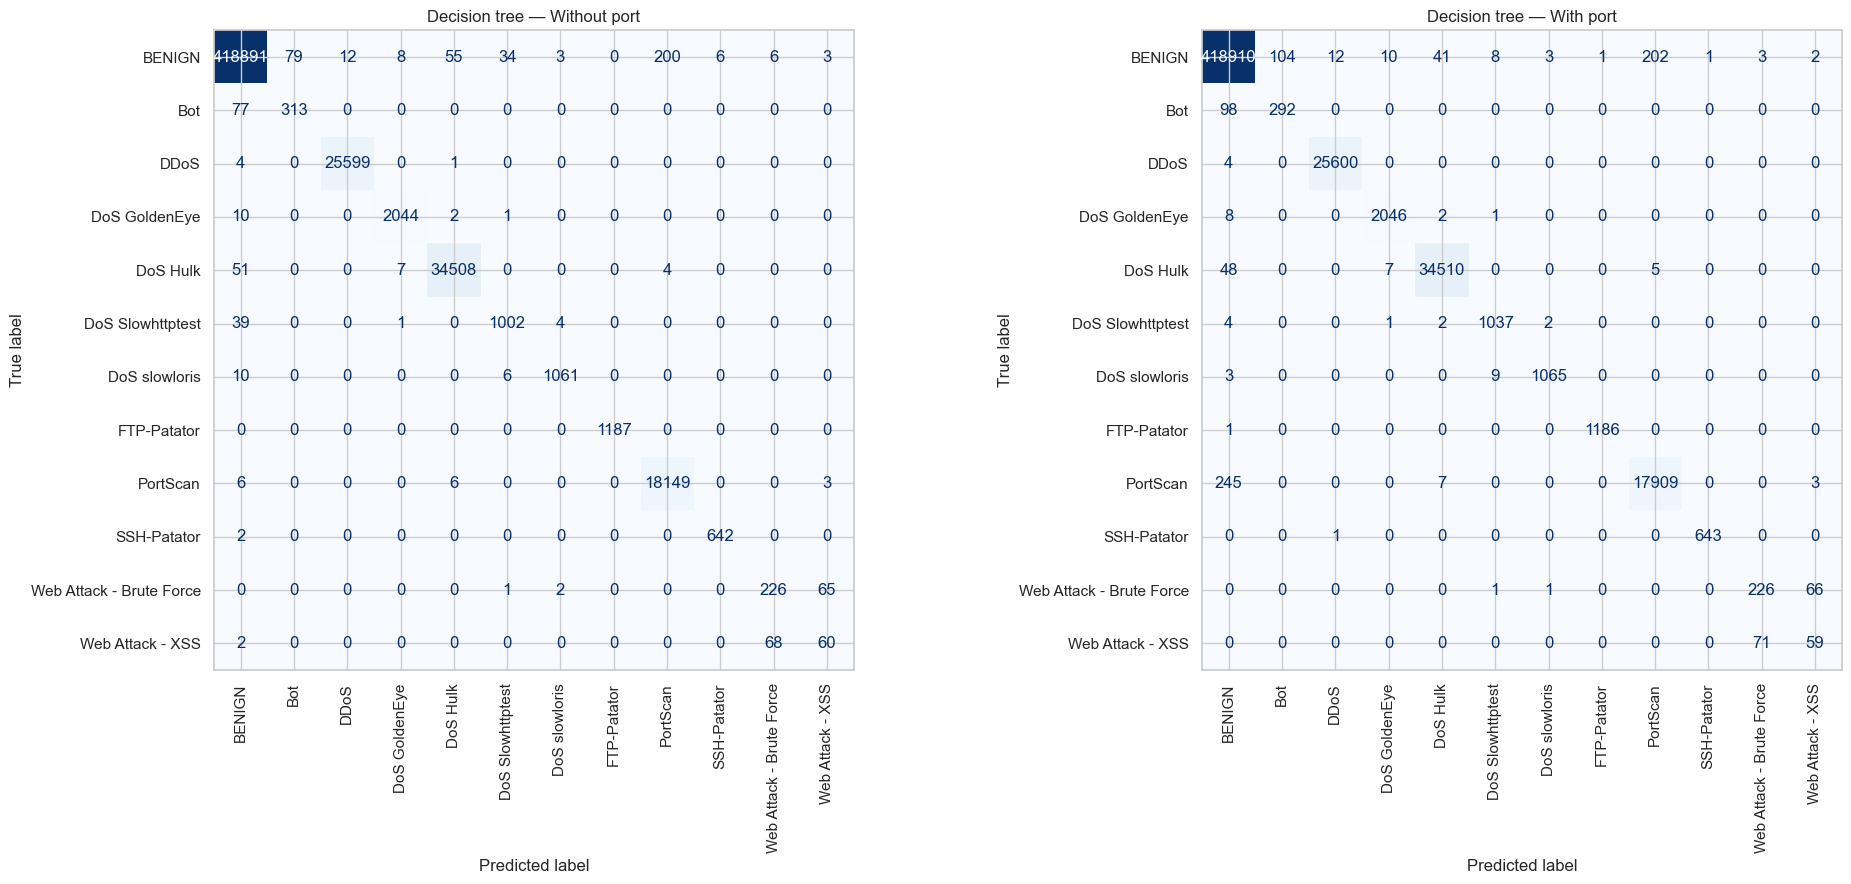

In [30]:
# Purpose: Compare frozen multiclass models with and without destination port on test.
# Explain: Report per-class changes, including zero recall; service associations may be collection-specific.

multiclass_models = {
    ("Without port", "Naive Bayes"): gnb_multiclass_model,
    ("Without port", "Logistic regression"): logistic_multiclass_numeric_model,
    ("Without port", "Decision tree"): tree_multiclass_numeric_model,
    ("With port", "Naive Bayes"): hybrid_multiclass_model,
    ("With port", "Logistic regression"): logistic_multiclass_complete_model,
    ("With port", "Decision tree"): tree_multiclass_complete_model,
}
multiclass_test_positions = np.flatnonzero(multiclass_test_keep)
multiclass_test_predictions = {
    key: np.empty(len(y_test_multiclass), dtype=object)
    for key in multiclass_models
}

for start in range(0, len(y_test_multiclass), TEST_BATCH_SIZE):
    stop = min(start + TEST_BATCH_SIZE, len(y_test_multiclass))
    positions = multiclass_test_positions[start:stop]
    numeric_batch = X_test_complete_numeric[positions]
    port_batch = X_test_port[positions]
    complete_batch = hstack(
        [csr_matrix(numeric_batch), port_batch],
        format="csr", dtype=np.float32,
    )
    for (representation, family), model in multiclass_models.items():
        if representation == "Without port":
            predictions = model.predict(numeric_batch)
        elif family == "Naive Bayes":
            predictions = model.predict(numeric_batch, port_batch)
        else:
            predictions = model.predict(complete_batch)
        multiclass_test_predictions[(representation, family)][
            start:stop
        ] = predictions

del numeric_batch, port_batch, complete_batch

multiclass_metric_rows = []
multiclass_recall_columns = {}
multiclass_confusion_matrices = {}

for (representation, family), predictions in (
    multiclass_test_predictions.items()
):
    multiclass_metric_rows.append({
        "representation": representation,
        "model": family,
        "macro_f1": f1_score(
            y_test_multiclass, predictions,
            labels=retained_multiclass_labels,
            average="macro", zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_test_multiclass, predictions
        ),
    })
    multiclass_recall_columns[(representation, family)] = recall_score(
        y_test_multiclass, predictions,
        labels=retained_multiclass_labels,
        average=None, zero_division=0,
    )
    multiclass_confusion_matrices[(representation, family)] = (
        confusion_matrix(
            y_test_multiclass, predictions,
            labels=retained_multiclass_labels,
        )
    )

part6_test_results = pd.DataFrame(multiclass_metric_rows).set_index(
    ["representation", "model"]
)
part6_class_recall = pd.DataFrame(
    multiclass_recall_columns, index=retained_multiclass_labels
)
part6_class_recall.index.name = "class"
part6_class_recall.columns.names = ["representation", "model"]
part6_port_recall_change = (
    part6_class_recall["With port"]
    - part6_class_recall["Without port"]
)

print("MULTICLASS TEST RESULTS")
display(part6_test_results)
print("CLASS-WISE RECALL")
display(part6_class_recall)
print("RECALL CHANGE FROM ADDING PORT — POSITIVE MEANS IMPROVEMENT")
display(part6_port_recall_change)

for family in ["Naive Bayes", "Logistic regression", "Decision tree"]:
    print(f"LARGEST ATTACK-RECALL CHANGES: {family}")
    changes = part6_port_recall_change[family].drop("BENIGN")
    display(changes.loc[
        changes.abs().sort_values(ascending=False).head(3).index
    ].to_frame("recall_change"))

for family in ["Naive Bayes", "Logistic regression", "Decision tree"]:
    fig, axes = plt.subplots(1, 2, figsize=(20, 9))
    for axis, representation in zip(axes, ["Without port", "With port"]):
        ConfusionMatrixDisplay(
            confusion_matrix=multiclass_confusion_matrices[
                (representation, family)
            ],
            display_labels=retained_multiclass_labels,
        ).plot(
            ax=axis, cmap="Blues", colorbar=False,
            xticks_rotation=90, values_format="d",
        )
        axis.set_title(f"{family} — {representation}")
    plt.tight_layout()
    plt.show()


### Interpretation

Macro-F1 gives each category equal weight, making failures on smaller attack categories visible even when BENIGN dominates the row count. The recall table shows which categories are missed, while confusion matrices show which labels replace them. Positive recall changes indicate categories helped by Destination Port; negative changes identify categories harmed by adding it. Inspect macro-F1 together with recall because a recall gain can accompany additional false positives for that category.

Port gains may reflect useful information about the targeted service, but may also reflect correlations specific to the CICIDS2017 collection setup. Strong performance on this random split does not establish that the same port associations will hold on a different day or network. The three largest absolute recall changes identify categories to discuss; their signs distinguish gains from losses. Keep model settings fixed after viewing these test results.

Being the majority gives BENIGN a larger prior, but that prior is only one part of Naive Bayes’s decision:
Two likely reasons explain this:

- BENIGN traffic is diverse. It includes many different behaviors. Modeling each numerical feature with one Gaussian per class can describe that diversity poorly.
- Many features are related. Naive Bayes treats them as independent, so several measurements can repeatedly push the prediction toward an attack category.

There are also 11 competing attack classes. A benign flow only needs one attack class to receive a higher score for it to be misclassified.